## Course Announcements

Due Sunday 11/22 (11:59 PM):
- A6
- EDA checkpoint
- Q8
- [weekly project survey](https://forms.gle/pRqEYm8rZQH4Ezcp7) (for EC)

Notes:
- **A8** (text analysis) is released this Fri and due *next* Sun (11/29). Today's notebook covers the code you need for it.
- Lecture this *Friday* will be pre-recorded \[to get lecture credit, after release, there will be a Google form to complete before Sun\]
- Data Checkpoint Scores + Feedback have been released

# Text Analysis (NLP: Natural Language Processing)

Today's question: **What do students like most and least about COGS 108, and how has that changed over time?**

We'll answer it twice, with the same data:

1. **Standard (deterministic) text analysis**: the same code on the same data always gives the same answer
    - cleaning text with **regular expressions**
    - **tokenization**, **stop words**, **stemming** & **lemmatization**
    - word frequencies
    - **sentiment analysis** with a lexicon (VADER)
    - **TF-IDF**: which words are most distinctive to each quarter?
2. **Generative AI**: a large language model (LLM) reads a sample of the responses and summarizes them

Then we'll compare the two: what each one does well, where each goes wrong, and how you'd check either one.

<div class="alert alert-info">

**A8:** Sections [5a](#s5a) (cleaning text with `re`) and [7](#s7) (TF-IDF with `TfidfVectorizer`) use the same steps as A8 Parts 1–3. Here, each document is a quarter of COGS 108 feedback; in A8, each document is an inaugural address.

</div>

On your own (end of notebook): who skips the "most" question, `max_features`, lemmas vs. stems, bigrams, running the GenAI prompt yourself, and a preview of using text in a machine learning model.

Tools: `re`, `nltk`, `scikit-learn`

## Contents

Reminder: In JupyterLab, the table of contents sidebar, the bulleted-list icon on the left, shows the same outline and highlights the section you're in.

- [1. Setup](#s1)
- [2. Text Analysis: The Big Picture](#s2)
- [3. The Data: COGS 108 Feedback, 2019–2026](#s3)
- [4. Words of Interest Over Time](#s4) · [4a. Counting Words](#s4a) · [4b. Regular Expressions](#s4b)
- [5. Preparing Text for Analysis](#s5) · [5a. Clean](#s5a) · [5b. Tokenize](#s5b) · [5c. Remove Stop Words](#s5c) · [5d. Stemming & Lemmatization](#s5d) · [5e. Most Common Words](#s5e)
- [6. Sentiment Analysis](#s6) · [6a. VADER](#s6a) · [6b. Sentiment of Every Response](#s6b) · [6c. Sentiment Over Time](#s6c)
- [7. TF-IDF: What's Distinctive About Each Quarter?](#s7) · [7a. One Document per Quarter](#s7a) · [7b. Calculate TF-IDF](#s7b) · [7c. Results](#s7c)
- [8. The Same Question, with GenAI](#s8) · [8a. The Sample & the Prompt](#s8a) · [8b. The GenAI Summary](#s8b) · [8c. Trust, but Verify](#s8c) · [8d. GenAI vs. VADER: Sentiment](#s8d)
- [9. Discussion: Standard Text Analysis vs. GenAI](#s9)
- [10. Summary: The Steps](#s10)
- [11. On Your Own](#s11) · [11a. Who Skips the "Most" Question?](#s11a) · [11b. `max_features`](#s11b) · [11c. Lemmas vs. Stems](#s11c) · [11d. Bigrams](#s11d) · [11e. Run the GenAI Prompt Yourself](#s11e) · [11f. Preview: Text as Features in a Model](#s11f)

## 1. Setup <a id="s1"></a>

In [1]:
# if you've never installed nltk before you will have to run this line once
# %pip install nltk

In [2]:
import re
import pandas as pd
import numpy as np

import seaborn as sns
sns.set_theme(style="white",
              font_scale=1.5,
              rc={'axes.spines.right': False, 'axes.spines.top': False})

import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (12, 6)

#improve resolution
#comment this line if erroring on your machine/screen
%config InlineBackend.figure_format ='retina'

import warnings
warnings.filterwarnings('ignore')

# show more of each response when displaying text
pd.set_option('display.max_colwidth', 200)

# natural language toolkit
import nltk
from nltk.tokenize import RegexpTokenizer, word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.probability import FreqDist
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# scikit-learn
from sklearn.feature_extraction.text import TfidfVectorizer

In [3]:
# download the nltk resources we'll use today (only downloads the first time)
# punkt/punkt_tab: tokenizer · stopwords · vader_lexicon: sentiment lexicon · wordnet: lemmatizer
for resource in ['punkt', 'punkt_tab', 'stopwords', 'vader_lexicon', 'wordnet']:
    nltk.download(resource, quiet=True)

## 2. Text Analysis: The Big Picture <a id="s2"></a>

**Natural Language Processing (NLP)** is a whole field of study. Like most topics in this course, there are entire courses on it. We'll cover the general concepts; know that you're missing lots of important details.

#### Examples of questions that require text analysis

- [How much of science is now written with LLMs?](https://pmc.ncbi.nlm.nih.gov/articles/PMC12219543/)
- Did J.K. Rowling write [*The Cuckoo's Calling*](https://www.scientificamerican.com/article/how-a-computer-program-helped-show-jk-rowling-write-a-cuckoos-calling/) under the pen name Robert Galbraith? *(an "authorial fingerprint": distributions of word lengths, the 100 most common words, character 4-grams, word bigrams)*
- Who has the [biggest vocabulary in hip hop](https://pudding.cool/projects/vocabulary/index.html)?
- Is there a [gender imbalance in who gets to say lines in movies](https://pudding.cool/2017/03/film-dialogue/)?

#### Text in your projects

Spam detection (texts, social media) · hate speech detection · predictive text · summarizing articles (TL;DR) or trends on social media · plagiarism detection · document similarity (e.g., catching duplicate questions on Piazza)

#### The steps

1. **Identify the problem** you're trying to solve. What you want to answer determines which of the steps below you need.
2. **Clean and preprocess** the data
3. **Linguistic transformations**: tokenization, stop words, stemming/lemmatization; *[optional]* part-of-speech tagging, named entity recognition
4. **EDA**
5. *[optional]* **Calculate measurements and statistics**: e.g., sentiment, TF-IDF, vocabulary diversity
6. *[optional]* **Transform the representation**: bag of words, vector embeddings
7. *[optional]* **Train a model** or write an algorithm to accomplish a task (e.g., detect spam)

We'll use `nltk`, the Natural Language Toolkit. The free [NLTK Book](http://www.nltk.org/book/) is a good next step if you want to go further.

## 3. The Data: COGS 108 Feedback, 2019–2026 <a id="s3"></a>

Every time I teach COGS 108, I ask students partway through the quarter what they've **enjoyed most** and what they've **liked least** so far. We have eight quarters of responses, including *this* quarter's.

In [4]:
# oldest to newest
quarters = ['Sp19', 'Wi20', 'Sp20', 'Fa20', 'Wi21', 'Wi24', 'Wi25', 'Fa26']

In [5]:
def read_data(quarter):
    '''read data in from specified quarter, extract columns of interest
    and add a column indicating quarter from which data originated'''

    df = pd.read_csv('data/COGS108_feedback_' + quarter + '.csv')
    df = df[['enjoyed_most', 'enjoyed_least']]
    df['quarter'] = quarter

    return df

In [6]:
# read in data for all quarters
df = pd.concat([read_data(quarter) for quarter in quarters], ignore_index=True)

# make quarter an ordered category, so tables and plots go oldest → newest
df['quarter'] = pd.Categorical(df['quarter'], categories=quarters, ordered=True)

df

,enjoyed_most,enjoyed_least,quarter
0,"No tests, project based class, optional lecture/discussion","Group projects can be rough, especially the beginning \nSection often has no purpose",Sp19
1,I enjoy learning how to use pandas through the assignments and the group project to do data wrangling and cleaning.,NaN,Sp19
2,No attendance,NaN,Sp19
3,Topics about how to handle several Python tools,nothing special,Sp19
4,I like the assignments. They're fun and have a good difficulty (challenging but also w/ good guidance) and they seem applicable which I like.\nI also appreciate not having to attend lecture but ...,Nothing!,Sp19
...,...,...,...
3440,Group work. I believe this helps with learning to work in groups in general and developing skills.,Participation tracking. Because I am unable to attend every session and sometimes need to watch podcasts instead since I commute and do not live on campus.,Fa26
3441,"I have enjoyed learning about all the different kinds of functions in R and how to use them. I wasn't familiar with seaborn, so it's been interesting learning how to use it. As well as our debate ...","Least liked would probably be learning how to use github, I am still getting used to how to use pull and push",Fa26
3442,"I really appreciate how we directly apply what we learn in class in both our assignments and group project. It is challenging, of course, but it is an opportunity to solidify certain concepts in m...","This is very nit picky, I just have been struggling to feel comfortable in the class and section. Especially since attendance has a high impact in the course and everyone is therefore normally pre...",Fa26
3443,"I like the way that the course is structured, I feel like it's given me a chance to learn new concepts and practice them during the assignments while also giving the flexibility to take late days ...","Accessing the lecture slides and the assignments is extremely frustrating, I would prefer it if all the information was on Canvas. It's caused me to forget to submit A1 and 2 because I assumed tha...",Fa26


In [7]:
# how many responses from each quarter?
df.value_counts('quarter', sort=False)

quarter
Sp19    384
Wi20    295
Sp20    397
Fa20    321
Wi21    314
Wi24    584
Wi25    690
Fa26    460
Name: count, dtype: int64

Response rates:
- Spring 2019: 384/826 (46%)
- Winter 2020: 295/444 (66%)
- Spring 2020: 397/475 (84%)
- Fall 2020: 321/447 (72%)
- Winter 2021: 314/438 (72%)
- Winter 2024: 584/701 (83%)
- Winter 2025: 690/817 (84%)
- **Fall 2026: 460/571 (81%)**

#### Data considerations

- Does this reflect reality? Who responds, and who doesn't?
- Duplicate responses?
- Missingness?
- Things change between quarters: remote vs. in person, labs vs. no labs, quizzes after every lecture vs. weekly. Keep that in mind when comparing over time.

In [8]:
# how many nonresponses?
df.isnull().sum()

enjoyed_most     141
enjoyed_least    318
quarter            0
dtype: int64

More students leave "least" blank than "most." (More on who skips "most" in [On Your Own](#s11a).)

In [9]:
# fill missing responses in the two text columns with an empty string
text_cols = ['enjoyed_most', 'enjoyed_least']
df[text_cols] = df[text_cols].fillna('')

#### Non-answers

Some students type "N/A", "nothing" or "no complaints" instead of leaving a question blank. pandas already reads a few exact strings ("N/A", "NA", "n/a", "None") as missing, but not "nothing", "N/a" or "Nope".

For "least," *nothing* is useful information (no complaints!), but these responses have no words to analyze, so we'll treat them as blank too, for every quarter. A regular expression (more on these in [4b](#s4b)) finds them.

In [10]:
# the whole response is a non-answer: n/a, none, nothing (so far, really, ...),
# no complaints, not sure... or it has no letters at all ("-", ":)")
non_answer = (r"[^a-z]*("
              r"n\W?a|none|nil|no|nope|idk|i don'?t know|not sure|"
              r"(nothing|notbing|notihign|none|not much|not really|not yet|no complaints?)"
              r"( (yet|so far|really|much|in particular|at all|for now|as of now|that i can think of"
              r"|to say|to be honest|worth noting|stands out|special))*"
              r")?[^a-z]*")

def is_non_answer(responses):
    '''True for responses that aren't blank but don't actually answer the question'''
    responses = responses.str.strip()
    return responses.str.fullmatch(non_answer, case=False) & (responses != '')

# how many non-answers in each quarter?
pd.DataFrame({col: is_non_answer(df[col]) for col in ['enjoyed_most', 'enjoyed_least']}).groupby(df['quarter'], observed=True).sum()

,enjoyed_most,enjoyed_least
quarter,,
Sp19,1,21
Wi20,0,8
Sp20,1,11
Fa20,0,13
Wi21,1,5
Wi24,0,19
Wi25,1,39
Fa26,0,22


In [11]:
# what we're removing (most common)
df.loc[is_non_answer(df['enjoyed_least']), 'enjoyed_least'].str.strip().value_counts().head(10)

enjoyed_least
Nothing            17
nothing            15
none               13
Nothing.            9
Nothing really      5
Nothing so far.     5
Nothing really.     4
Nothing!            4
Nothing so far      4
N/a                 3
Name: count, dtype: int64

In [12]:
# treat non-answers as blank
for col in ['enjoyed_most', 'enjoyed_least']:
    df.loc[is_non_answer(df[col]), col] = ''

## 4. Words of Interest Over Time <a id="s4"></a>

Before any NLP, the simplest text analysis is: **what fraction of responses mention a word?**

### 4a. Counting Words <a id="s4a"></a>

In [13]:
def check_word_freq(df, word):
    '''proportion of responses in each quarter whose most/least response contains `word`
    (case-insensitive). `word` can be a plain string or a regular expression.'''

    most = df.groupby('quarter', observed=True)['enjoyed_most'].apply(lambda s: s.str.contains(word, case=False).mean())
    least = df.groupby('quarter', observed=True)['enjoyed_least'].apply(lambda s: s.str.contains(word, case=False).mean())

    return pd.DataFrame({'most': most, 'least': least}).round(3)


def plot_word_freq(df, word):
    '''line plot of check_word_freq over quarters'''
    check_word_freq(df, word).plot(marker='o')
    plt.ylabel('proportion of responses')
    plt.xlabel('')
    plt.title(f'Responses mentioning "{word}"');

In [14]:
check_word_freq(df, 'quiz')

,most,least
quarter,,
Sp19,0.000,0.000
Wi20,0.017,0.061
Sp20,0.068,0.363
Fa20,0.065,0.302
Wi21,0.000,0.089
Wi24,0.010,0.072
Wi25,0.019,0.051
Fa26,0.017,0.052


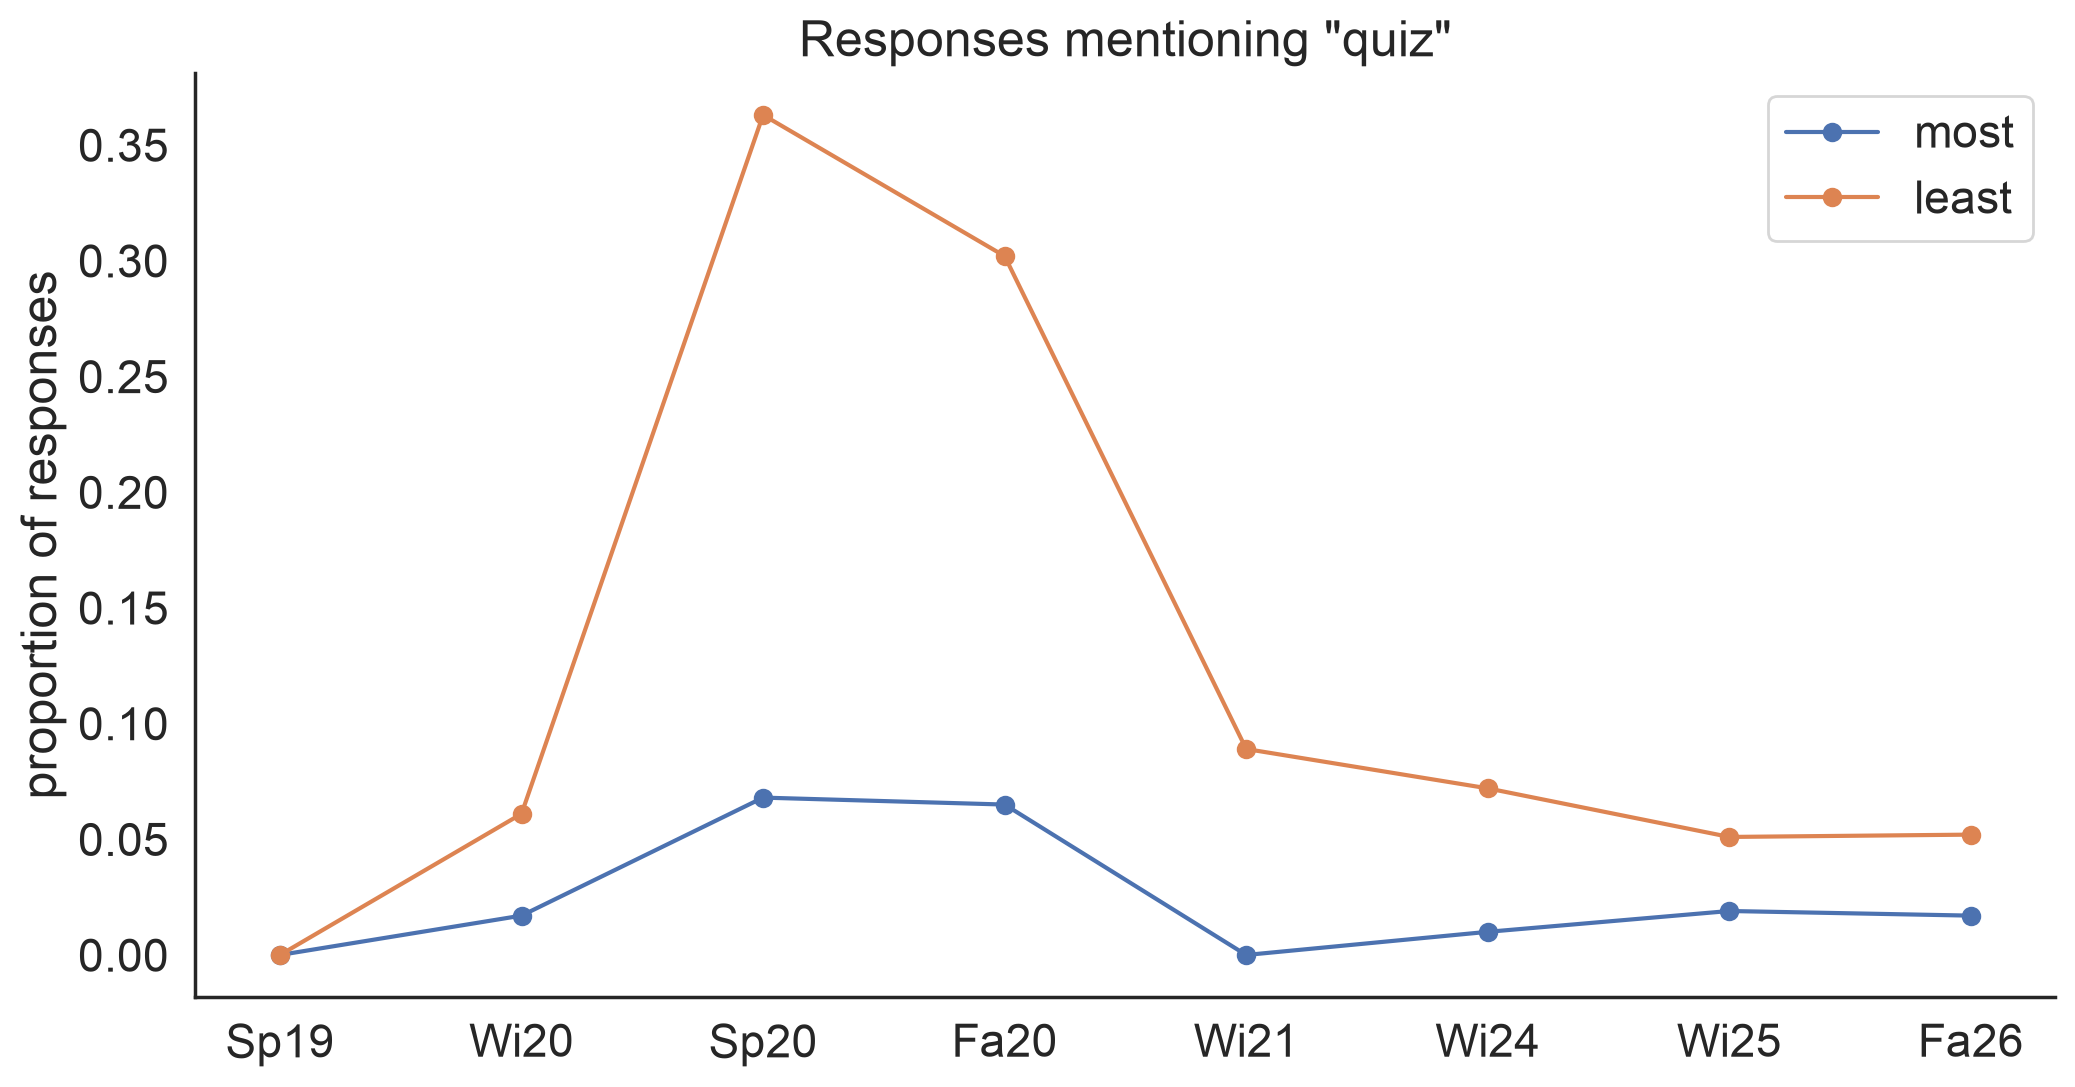

In [15]:
plot_word_freq(df, 'quiz')

Quizzes after each lecture video were introduced during remote learning during the pandemic (Sp20, Fa20)

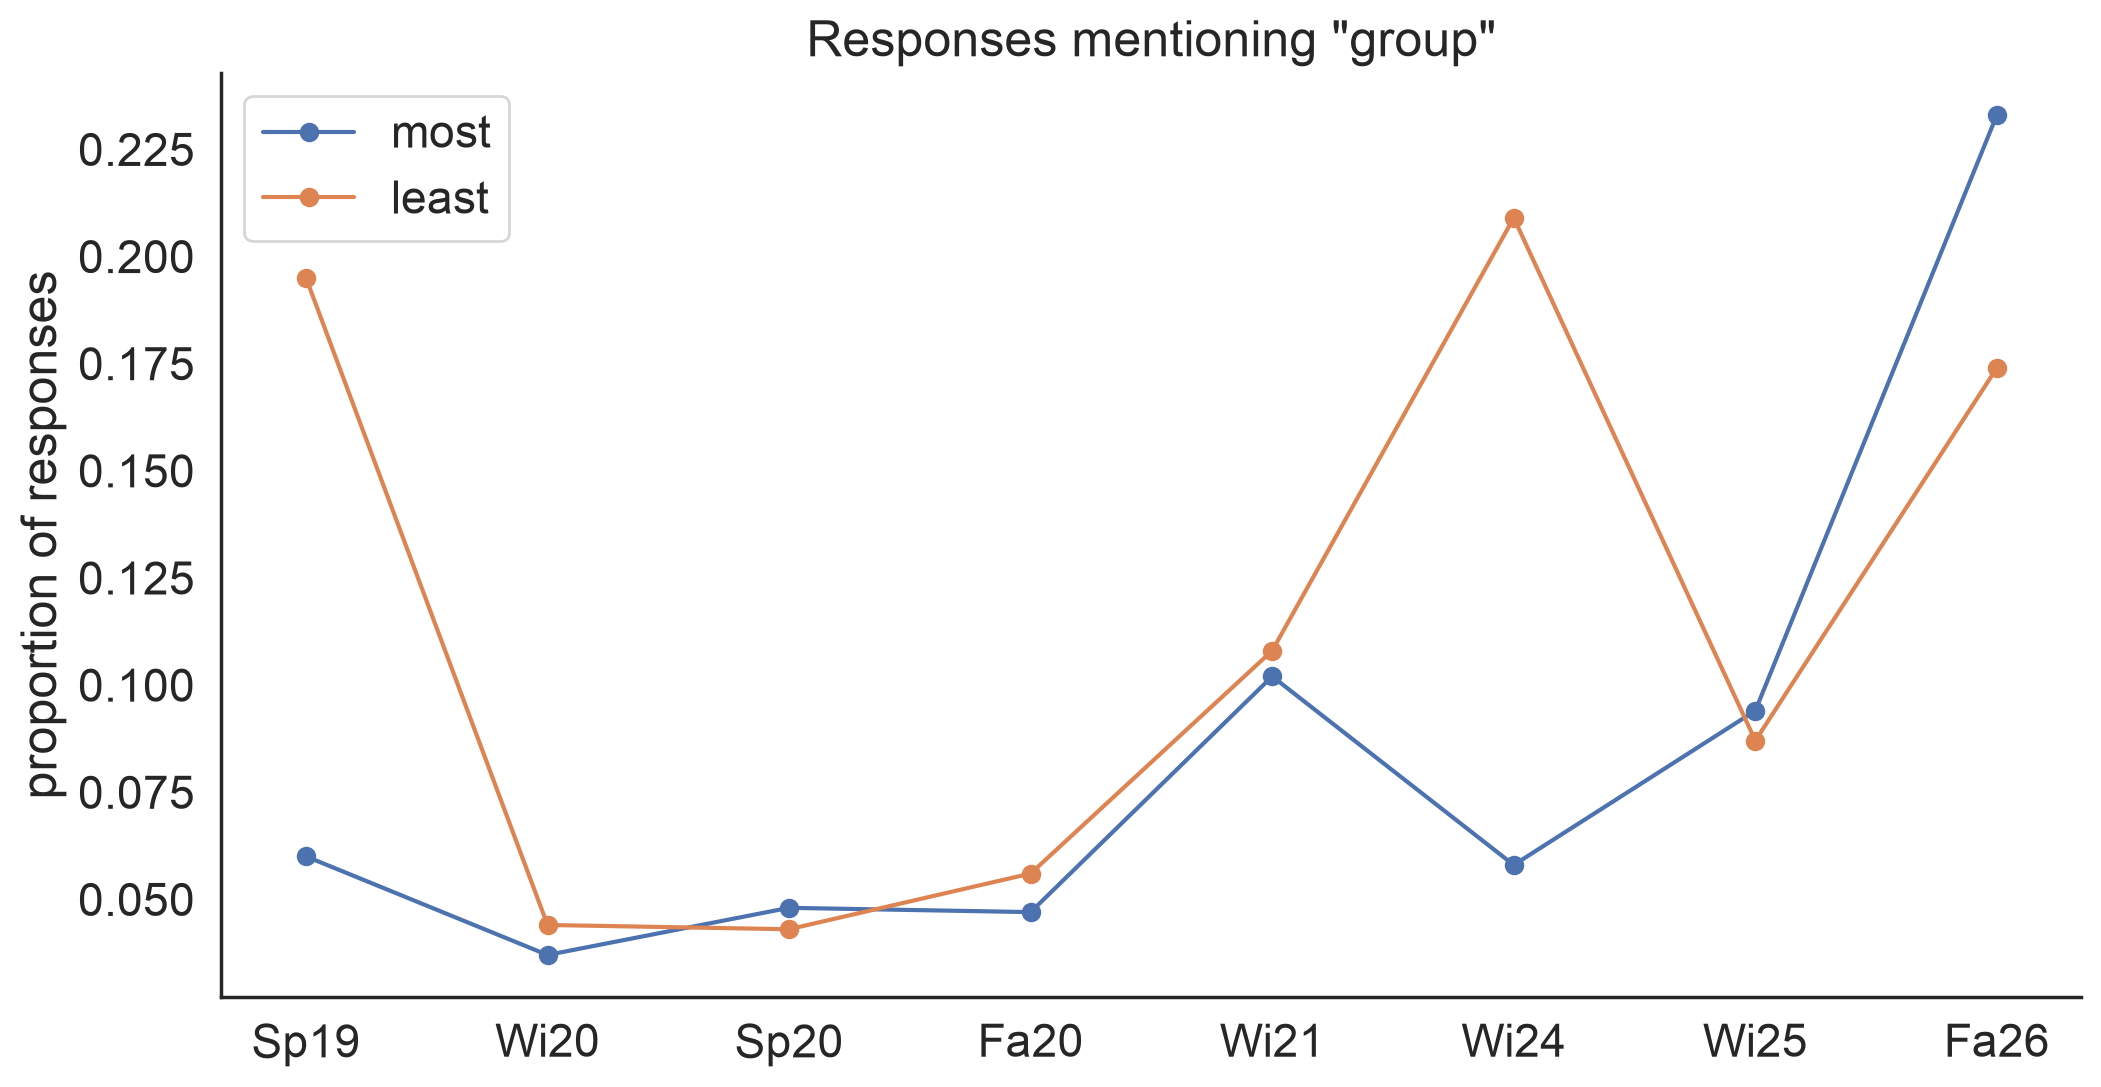

In [16]:
plot_word_freq(df, 'group')

We assigned groups in Sp19 and Wi24...

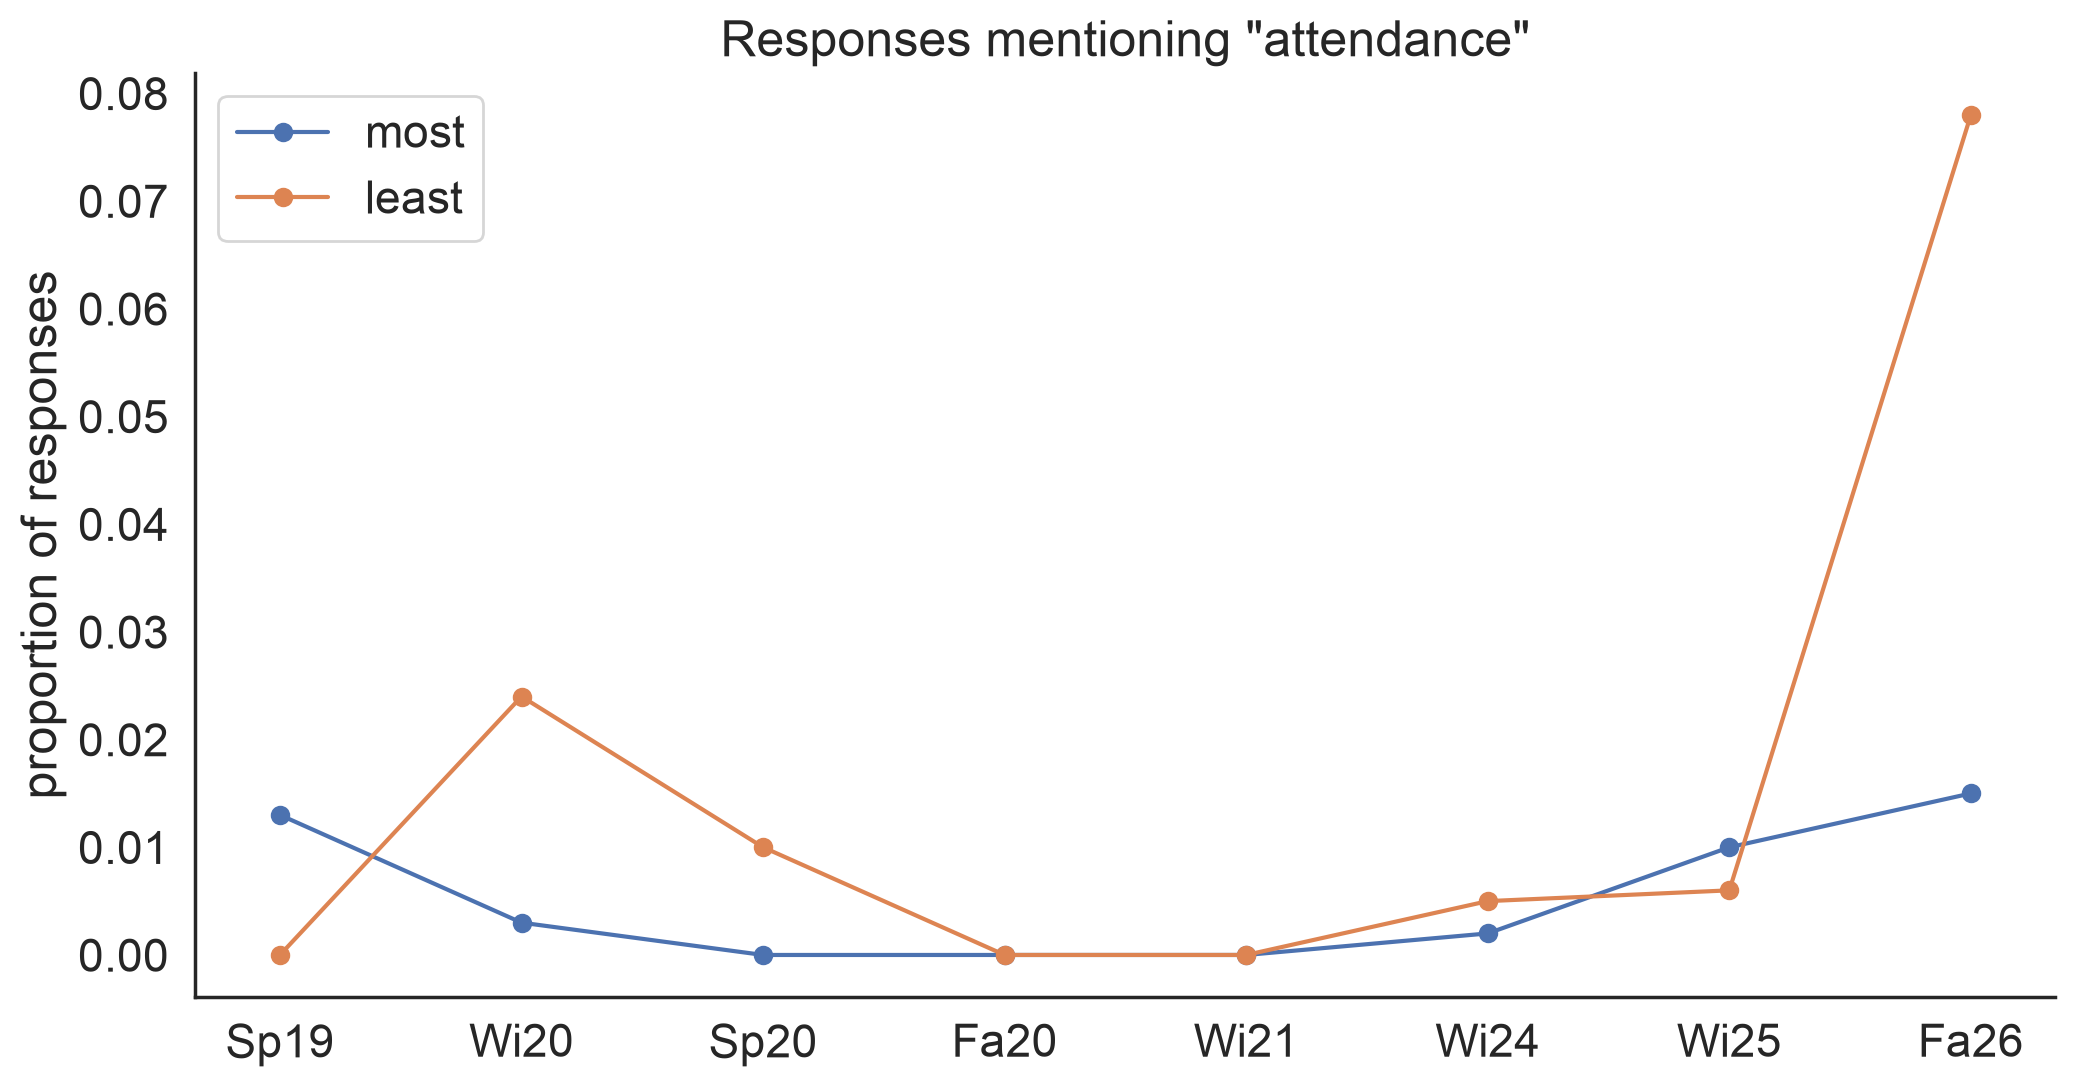

In [17]:
plot_word_freq(df, 'attendance')

Well....you're all here. You know what this means.

What about AI? ChatGPT was released in November 2022, so we'd expect mentions of AI only in Wi24 and later.

In [18]:
check_word_freq(df, 'ai')

,most,least
quarter,,
Sp19,0.055,0.039
Wi20,0.058,0.047
Sp20,0.091,0.088
Fa20,0.075,0.112
Wi21,0.061,0.102
Wi24,0.077,0.098
Wi25,0.107,0.087
Fa26,0.087,0.089


#### Question #1

<img src="QRCodes/14_01.png" width="240" align="right">

About 5–10% of responses mention "ai" in *every* quarter, including Spring 2019, years before ChatGPT. What's the most likely explanation?

- A) Students were already using AI tools for COGS 108 in 2019
- B) `str.contains` matches "ai" *inside* other words, like "expl**ai**ned" and "det**ai**l"
- C) The quarters got mislabeled when the data were combined
- D) We didn't remove stop words first

Poll: https://forms.gle/BbcerCh76p6Dcqbt7

In [19]:
# what's being matched in Spring 2019?
sp19_most = df.loc[df['quarter'] == 'Sp19', 'enjoyed_most']
sp19_most[sp19_most.str.contains('ai', case=False)].head()

8                                                                                 Detailed examples of working through data science problems 
9                   Brainstorming all the different variables that can affect the thing we are trying to measure in the data science question
10                                                                              Nice intro to Data Science, try to explain the basic concepts
14    I like the idea of having a group project, because that creates an environment for students to gain experience with working on a team. 
22                                                                                  Analysis those data by certain code make me feel amazing 
Name: enjoyed_most, dtype: object

### 4b. Regular Expressions <a id="s4b"></a>

A **regular expression** (regex) is a pattern for matching text. `str.contains()` treats its argument as a regex by default, and Python's `re` module uses the same patterns.

| Pattern | Matches | Example |
|---|---|---|
| `\b` | a word boundary (start or end of a word) | `r'\bai\b'` matches "ai" but not "said" |
| `\|` | or | `r'quiz\|exam'` |
| `?` | the previous character is optional | `r'llms?'` matches "llm" and "llms" |
| `[^a-z]` | any character that is *not* a–z | |
| `+` | one or more of the previous thing | `r'[^a-z]+'` matches a run of non-letters |
| `\s` | whitespace (space, tab, newline) | |

Write regex patterns as raw strings, `r'...'`, so Python doesn't treat `\b` as a special character.

In [20]:
# "ai" as its own word, or chatgpt, or llm(s)
check_word_freq(df, r'\bai\b|chatgpt|\bllms?\b')

,most,least
quarter,,
Sp19,0.000,0.000
Wi20,0.000,0.000
Sp20,0.000,0.000
Fa20,0.000,0.000
Wi21,0.000,0.000
Wi24,0.000,0.002
Wi25,0.000,0.000
Fa26,0.011,0.022


That's more like it: essentially zero until this quarter.

<div class="alert alert-warning">

**Check what your pattern matched**, not just how many times it matched. Substring matches like "ai" in "explained" (or "lab" in "collaborate" and "available") silently inflate counts.

</div>

## 5. Preparing Text for Analysis <a id="s5"></a>

Counting a hand-picked word only answers questions you already thought to ask. To let the words in the data speak for themselves, we first turn each response into a clean list of meaningful words.

We'll walk through each step on one response, then apply it to every response.

**General Process**:  
a. Clean  
b. Tokenize  
c. Remove Stop Words  
d. Stemming & Lemmatization  

In [21]:
example = df.loc[df['enjoyed_least'].str.startswith('Desperately trying'), 'enjoyed_least'].iloc[0]
example

"Desperately trying to race to class in order to get a seat before I'm delegated to the cold hard floor."

### 5a. Clean <a id="s5a"></a>

Lowercase everything (so "Lecture" and "lecture" count as the same word) and replace punctuation with spaces using `re.sub()`.

In [22]:
def clean_text(text):
    '''lowercase, replace anything that isn't a letter or digit with a space,
    and strip spaces from the ends'''
    text = text.lower()
    text = re.sub(r'[^a-z0-9]+', ' ', text)
    return text.strip()

clean_text(example)

'desperately trying to race to class in order to get a seat before i m delegated to the cold hard floor'

Note what happened to "I'm": it's now two tokens, "i" and "m". Every cleaning choice has side effects like this.

<div class="alert alert-info">

**A8:** Question 1c asks you to clean the inaugural addresses the same way: remove punctuation with the `re` module and make everything lowercase, with words separated by single spaces.

</div>

### 5b. Tokenize <a id="s5b"></a>

A **token** is a meaningful unit of text: what you'll use for analysis. **Tokenization** splits text into tokens (words, bigrams, sentences, etc.).

In [23]:
# split on anything that isn't a "word character" (letters, digits, underscore)
tokenizer = RegexpTokenizer(r'\w+')
print(tokenizer.tokenize(example))

# nltk's word tokenizer keeps punctuation and splits contractions: I'm → I + 'm
print(word_tokenize(example))

['Desperately', 'trying', 'to', 'race', 'to', 'class', 'in', 'order', 'to', 'get', 'a', 'seat', 'before', 'I', 'm', 'delegated', 'to', 'the', 'cold', 'hard', 'floor']
['Desperately', 'trying', 'to', 'race', 'to', 'class', 'in', 'order', 'to', 'get', 'a', 'seat', 'before', 'I', "'m", 'delegated', 'to', 'the', 'cold', 'hard', 'floor', '.']


In [24]:
# on the cleaned text, both give the same result
print(word_tokenize(clean_text(example)))

['desperately', 'trying', 'to', 'race', 'to', 'class', 'in', 'order', 'to', 'get', 'a', 'seat', 'before', 'i', 'm', 'delegated', 'to', 'the', 'cold', 'hard', 'floor']


In [25]:
# tokenize every response (cleaned first)
df['most_tokens'] = df['enjoyed_most'].apply(clean_text).apply(word_tokenize)
df['least_tokens'] = df['enjoyed_least'].apply(clean_text).apply(word_tokenize)
df[['enjoyed_least', 'least_tokens']].tail()

,enjoyed_least,least_tokens
3440,Participation tracking. Because I am unable to attend every session and sometimes need to watch podcasts instead since I commute and do not live on campus.,"[participation, tracking, because, i, am, unable, to, attend, every, session, and, sometimes, need, to, watch, podcasts, instead, since, i, commute, and, do, not, live, on, campus]"
3441,"Least liked would probably be learning how to use github, I am still getting used to how to use pull and push","[least, liked, would, probably, be, learning, how, to, use, github, i, am, still, getting, used, to, how, to, use, pull, and, push]"
3442,"This is very nit picky, I just have been struggling to feel comfortable in the class and section. Especially since attendance has a high impact in the course and everyone is therefore normally pre...","[this, is, very, nit, picky, i, just, have, been, struggling, to, feel, comfortable, in, the, class, and, section, especially, since, attendance, has, a, high, impact, in, the, course, and, everyo..."
3443,"Accessing the lecture slides and the assignments is extremely frustrating, I would prefer it if all the information was on Canvas. It's caused me to forget to submit A1 and 2 because I assumed tha...","[accessing, the, lecture, slides, and, the, assignments, is, extremely, frustrating, i, would, prefer, it, if, all, the, information, was, on, canvas, it, s, caused, me, to, forget, to, submit, a1..."
3444,"I dislike the assignments, datahub is not that easy to use.","[i, dislike, the, assignments, datahub, is, not, that, easy, to, use]"


### 5c. Remove Stop Words <a id="s5c"></a>

**Stop words** are extremely common words that usually aren't helpful for analysis: "the", "of", "to", "is"... Removing them leaves the words that carry the content (and less to compute).

In [26]:
stop_words = set(stopwords.words('english'))
print(len(stop_words), 'stop words, e.g.:', sorted(stop_words)[:30])

198 stop words, e.g.: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't"]


In [27]:
example_tokens = word_tokenize(clean_text(example))
example_words = [word for word in example_tokens if word not in stop_words]

print('Tokens:          ', example_tokens)
print('No stop words:   ', example_words)

Tokens:           ['desperately', 'trying', 'to', 'race', 'to', 'class', 'in', 'order', 'to', 'get', 'a', 'seat', 'before', 'i', 'm', 'delegated', 'to', 'the', 'cold', 'hard', 'floor']
No stop words:    ['desperately', 'trying', 'race', 'class', 'order', 'get', 'seat', 'delegated', 'cold', 'hard', 'floor']


In [28]:
# is "not" a stop word?
'not' in stop_words, 'no' in stop_words

(True, True)

<div class="alert alert-warning">

"not" and "no" are stop words in this list. For counting topics that's fine, but for **sentiment**, removing "not" turns "not helpful" into "helpful." Choose (or edit) your stop word list for your question.

</div>

In [29]:
# remove stop words from every response
df['most_words'] = df['most_tokens'].apply(lambda tokens: [w for w in tokens if w not in stop_words])
df['least_words'] = df['least_tokens'].apply(lambda tokens: [w for w in tokens if w not in stop_words])

df[['least_tokens', 'least_words']].tail()

,least_tokens,least_words
3440,"[participation, tracking, because, i, am, unable, to, attend, every, session, and, sometimes, need, to, watch, podcasts, instead, since, i, commute, and, do, not, live, on, campus]","[participation, tracking, unable, attend, every, session, sometimes, need, watch, podcasts, instead, since, commute, live, campus]"
3441,"[least, liked, would, probably, be, learning, how, to, use, github, i, am, still, getting, used, to, how, to, use, pull, and, push]","[least, liked, would, probably, learning, use, github, still, getting, used, use, pull, push]"
3442,"[this, is, very, nit, picky, i, just, have, been, struggling, to, feel, comfortable, in, the, class, and, section, especially, since, attendance, has, a, high, impact, in, the, course, and, everyo...","[nit, picky, struggling, feel, comfortable, class, section, especially, since, attendance, high, impact, course, everyone, therefore, normally, present, struggle, focus, learning, cramped, space, ..."
3443,"[accessing, the, lecture, slides, and, the, assignments, is, extremely, frustrating, i, would, prefer, it, if, all, the, information, was, on, canvas, it, s, caused, me, to, forget, to, submit, a1...","[accessing, lecture, slides, assignments, extremely, frustrating, would, prefer, information, canvas, caused, forget, submit, a1, 2, assumed, gets, submitted, save]"
3444,"[i, dislike, the, assignments, datahub, is, not, that, easy, to, use]","[dislike, assignments, datahub, easy, use]"


### 5d. Stemming & Lemmatization <a id="s5d"></a>

Many words share a root: jumping, jumped, jumps and jump all come from "jump". Mapping each token to its root lets them be counted together.

- **Stemming** chops off endings using rules. Fast, word-by-word, and crude: the stem isn't always a real word.
- **Lemmatization** looks words up in a dictionary to find the real root word (the *lemma*), and can use context like part of speech.

Where it gets tricky: **jumper**. "I love my new jumper" (a sweater in the UK, a dress in the US) and "Shane is a long jumper" need different roots. A lemmatizer that's told the context can handle this; a stemmer can't.

In [30]:
ps = PorterStemmer()
lemmatizer = WordNetLemmatizer()

words = ['quizzes', 'quiz', 'studies', 'studying', 'organized', 'organization', 'was', 'jumping', 'jumper']

pd.DataFrame({'word': words,
              'stem': [ps.stem(w) for w in words],
              'lemma': [lemmatizer.lemmatize(w) for w in words],
              'lemma (as a verb)': [lemmatizer.lemmatize(w, pos='v') for w in words]})

,word,stem,lemma,lemma (as a verb)
0,quizzes,quizz,quiz,quiz
1,quiz,quiz,quiz,quiz
2,studies,studi,study,study
3,studying,studi,studying,study
4,organized,organ,organized,organize
5,organization,organ,organization,organization
6,was,wa,wa,be
7,jumping,jump,jumping,jump
8,jumper,jumper,jumper,jumper


#### Question #2

<img src="QRCodes/14_02.png" width="340" align="right">

Based on the table above, which statement is true?

- A) Stemming always returns a real English word
- B) The lemmatizer maps "quizzes" and "quiz" to the same token, but the stemmer doesn't
- C) Lemmatizing "studying" gives "study" even without telling it the part of speech
- D) Both tools leave "organized" and "organization" as two different tokens

Poll: https://forms.gle/gQGe8tPqraXP45YZ9

In [31]:
# stem every response
df['most_stems'] = df['most_words'].apply(lambda words: [ps.stem(w) for w in words])
df['least_stems'] = df['least_words'].apply(lambda words: [ps.stem(w) for w in words])

df[['least_words', 'least_stems']].tail()

,least_words,least_stems
3440,"[participation, tracking, unable, attend, every, session, sometimes, need, watch, podcasts, instead, since, commute, live, campus]","[particip, track, unabl, attend, everi, session, sometim, need, watch, podcast, instead, sinc, commut, live, campu]"
3441,"[least, liked, would, probably, learning, use, github, still, getting, used, use, pull, push]","[least, like, would, probabl, learn, use, github, still, get, use, use, pull, push]"
3442,"[nit, picky, struggling, feel, comfortable, class, section, especially, since, attendance, high, impact, course, everyone, therefore, normally, present, struggle, focus, learning, cramped, space, ...","[nit, picki, struggl, feel, comfort, class, section, especi, sinc, attend, high, impact, cours, everyon, therefor, normal, present, struggl, focu, learn, cramp, space, sit, group, discuss]"
3443,"[accessing, lecture, slides, assignments, extremely, frustrating, would, prefer, information, canvas, caused, forget, submit, a1, 2, assumed, gets, submitted, save]","[access, lectur, slide, assign, extrem, frustrat, would, prefer, inform, canva, caus, forget, submit, a1, 2, assum, get, submit, save]"
3444,"[dislike, assignments, datahub, easy, use]","[dislik, assign, datahub, easi, use]"


### 5e. Most Common Words <a id="s5e"></a>

`FreqDist` counts how often each token appears. Let's compare this quarter's "most" and "least" responses (words with stop words removed; stems are harder to read).

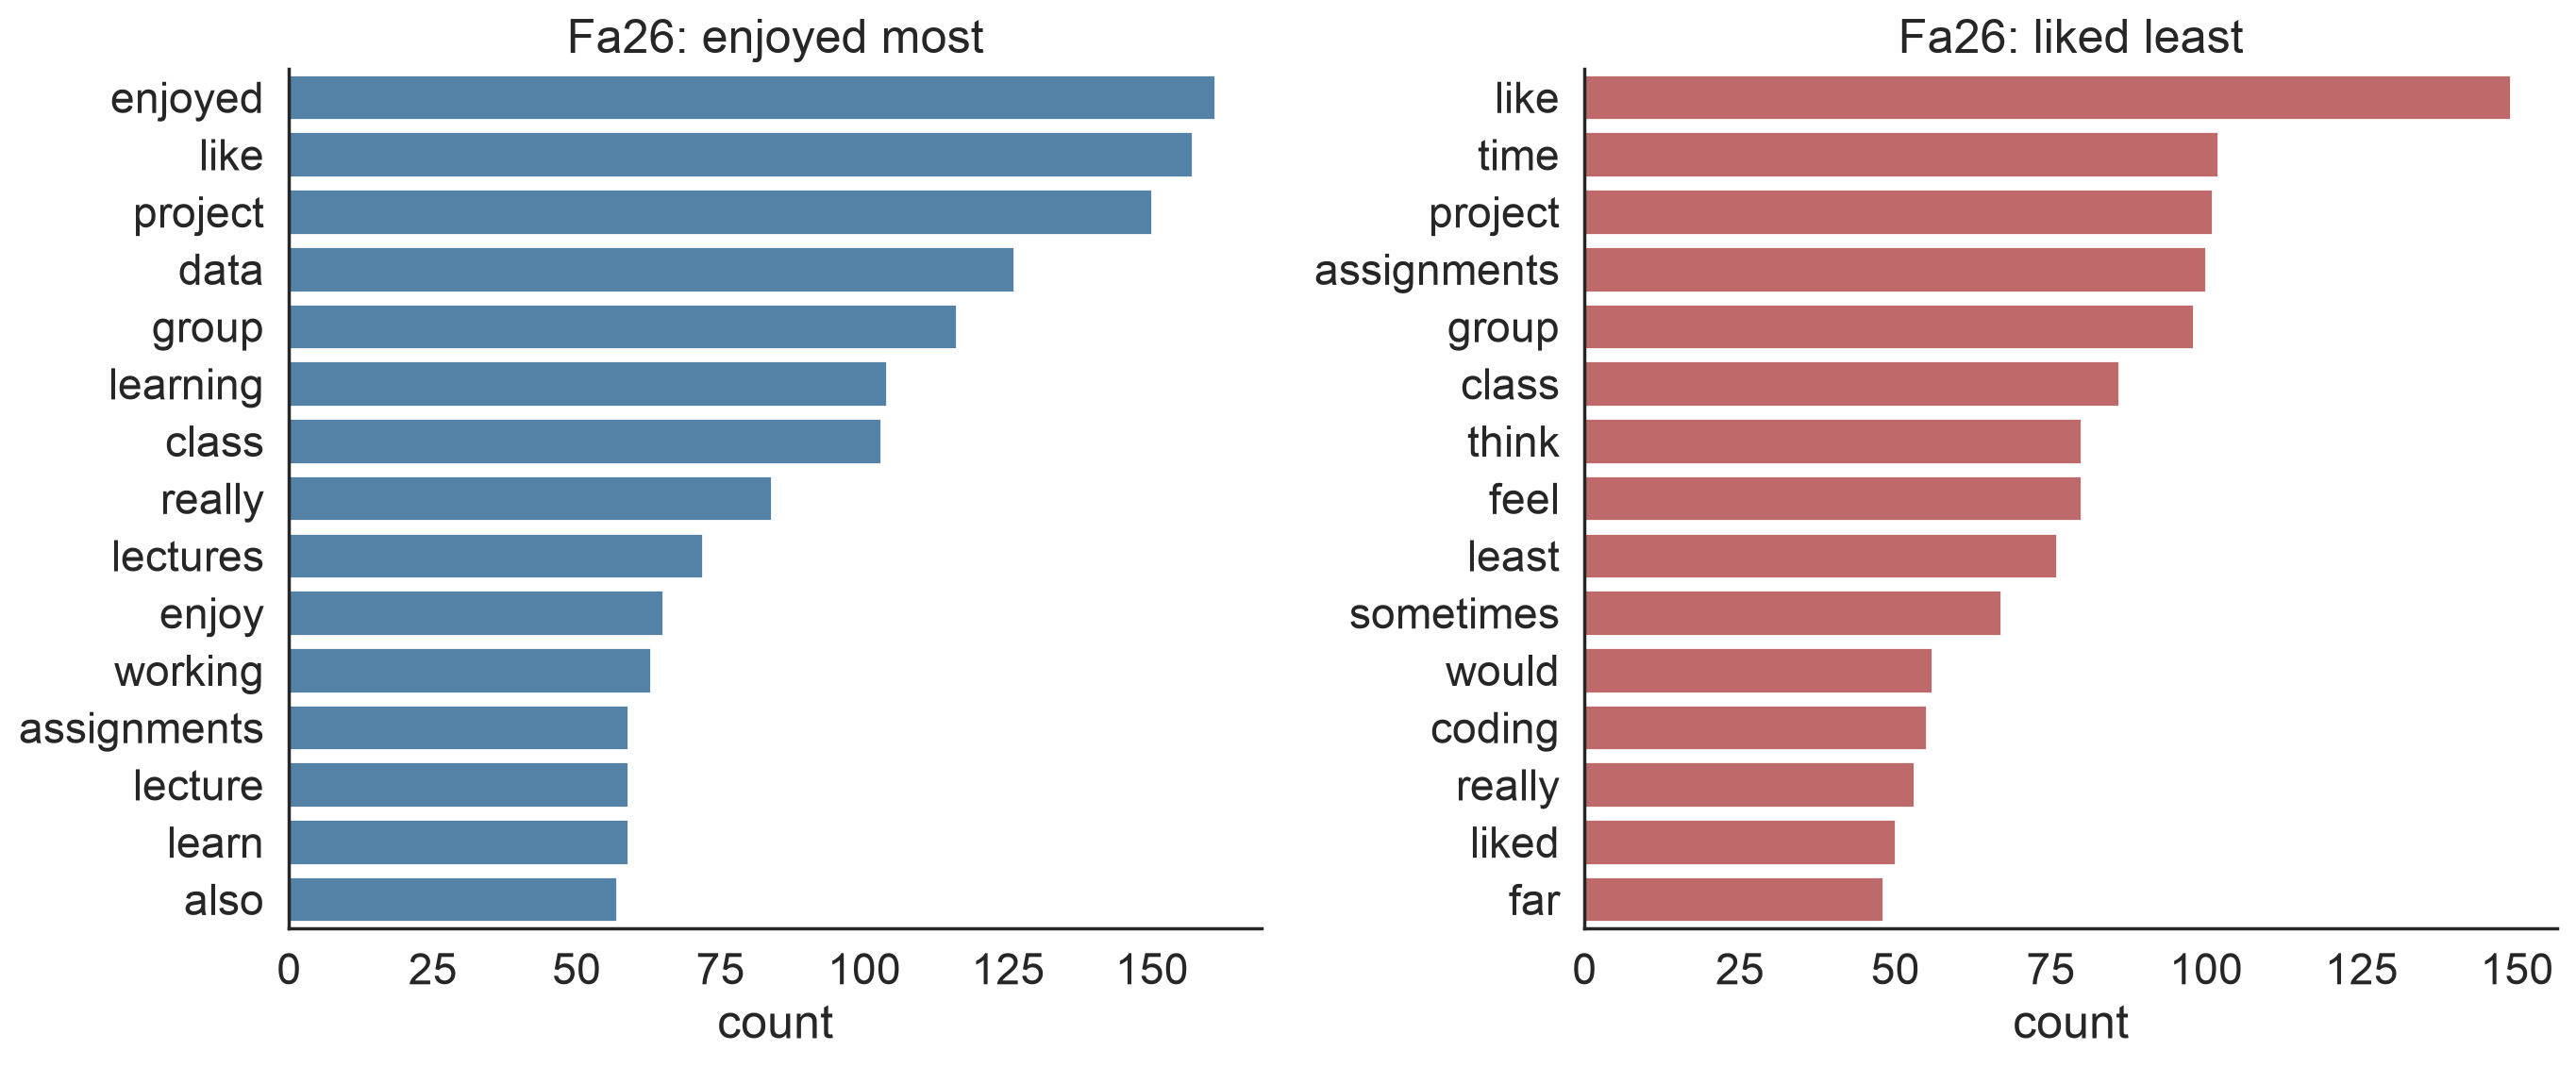

In [32]:
def top_words(token_lists, n=15):
    '''the n most common tokens across a series of token lists'''
    counts = FreqDist(token for tokens in token_lists for token in tokens)
    return pd.DataFrame(counts.most_common(n), columns=['word', 'count'])

fa26 = df[df['quarter'] == 'Fa26']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=top_words(fa26['most_words']), y='word', x='count', ax=axes[0], color='steelblue')
axes[0].set_title('Fa26: enjoyed most')
sns.barplot(data=top_words(fa26['least_words']), y='word', x='count', ax=axes[1], color='indianred')
axes[1].set_title('Fa26: liked least')
for ax in axes: ax.set_ylabel('')
plt.tight_layout();

"like", "least" and "liked" top the "least" list because students repeat the survey question in their answers ("What I liked least is..."). For this data, you might add them to your stop words.

<div class="alert alert-warning">

**In text analysis, your choices matter:** how to tokenize? remove stop words, and which ones? stem, lemmatize, or neither? which lexicon? Each choice changes your results, so make them on purpose and report them.

</div>

## Course Announcements

Due Sunday 11/22 (11:59 PM):
- A6
- EDA checkpoint
- Q8
- [weekly project survey](https://forms.gle/pRqEYm8rZQH4Ezcp7) (for EC)
- "lecture attendance" (single form submission) for Geospatial Analysis Lecture [*No in-class lecture Fri*]

Notes:
- My **office hours canceled for today** (apologies!)
- lecture + section **attendance** updated in Canvas through last Friday (end of week 7)
- **A5** scores + feedback were released [but we're looking into an autograder issue; hold off on regrade requests]
- sign ups and process for **oral exams** in week 10 will be discussed in class Mon (after which you'll be able to sign up)
- optional A7 now available on datahub

## 6. Sentiment Analysis <a id="s6"></a>

**Sentiment analysis** programmatically infers the emotional content of text. Two general approaches:

1. **Lexicon-based**: break the text into tokens and look each one up in a **sentiment lexicon**, a dataset of words labeled by their sentiment (e.g., "great" = positive, "boring" = negative). Combine the scores.
2. **Machine learning-based**: train a classification model on text that people have already labeled.

(GenAI models are a third option. We'll come back to them in [Section 8](#s8d).)

### 6a. VADER <a id="s6a"></a>

[VADER](https://github.com/cjhutto/vaderSentiment) is a lexicon (plus rules) built for short, informal text like social media posts and reviews. It handles:

- capitalization (great vs. GREAT) and punctuation (an exclamation point makes it more positive!)
- emojis and emoticons
- degree modifiers (extremely good vs. marginally good)
- negation and conjunctions ("but" signals a shift)

It returns `pos` + `neg` + `neu` (proportions that add to 1) and a **`compound`** score: the sum of the lexicon ratings, normalized to between −1 (most negative) and +1 (most positive).
- positive: `compound` ≥ 0.05
- neutral: −0.05 < `compound` < 0.05
- negative: `compound` ≤ −0.05

In [33]:
analyser = SentimentIntensityAnalyzer()

analyser.polarity_scores("The class is super cool.")

{'neg': 0.0, 'neu': 0.326, 'pos': 0.674, 'compound': 0.7351}

In [34]:
analyser.polarity_scores("The class is not super cool.")

{'neg': 0.561, 'neu': 0.439, 'pos': 0.0, 'compound': -0.6259}

In [35]:
analyser.polarity_scores("The class is NOT super cool!")

{'neg': 0.574, 'neu': 0.426, 'pos': 0.0, 'compound': -0.6597}

**Your turn:** before running the next cell, how would *you* classify this sentence: positive, negative, neutral, or other?

> "The project idea was great, but the workload could have been better."

In [36]:
analyser.polarity_scores("The project idea was great, but the workload could have been better.")

{'neg': 0.0, 'neu': 0.61, 'pos': 0.39, 'compound': 0.7506}

VADER calls it strongly positive: "great" and "better" are both positive words in the lexicon, and it doesn't understand that "could have been better" is a complaint.

#### Question #3

<img src="QRCodes/14_03.png" width="600" align="right">

What is a limitation of lexicon-based sentiment analysis?

- A) Words in your dataset may not all be included in the lexicon
- B) Context in language matters, but may be lost in sentiment analysis
- C) The lexicon may misclassify the sentiment of the words in your dataset
- D) The results you get are sensitive to the lexicon you use for your analysis
- E) All of the above

Poll: https://forms.gle/d5AAgbkgJkesPyqWA

### 6b. Sentiment of Every Response <a id="s6b"></a>

VADER works on the original text (it uses capitalization, punctuation and "not"), so we score the raw responses, not the cleaned tokens.

In [37]:
def get_compound(text):
    '''VADER compound score for a piece of text'''
    return analyser.polarity_scores(text)['compound']

# one row per response: quarter, which question, the text, and its compound score
sentiment = pd.concat([
    pd.DataFrame({'quarter': df['quarter'], 'question': 'most', 'response': df['enjoyed_most']}),
    pd.DataFrame({'quarter': df['quarter'], 'question': 'least', 'response': df['enjoyed_least']})
], ignore_index=True)

# leave out blank responses
sentiment = sentiment[sentiment['response'] != '']

sentiment['compound'] = sentiment['response'].apply(get_compound)
sentiment.head()

,quarter,question,response,compound
0,Sp19,most,"No tests, project based class, optional lecture/discussion",-0.2960
1,Sp19,most,I enjoy learning how to use pandas through the assignments and the group project to do data wrangling and cleaning.,0.4939
2,Sp19,most,No attendance,-0.2960
3,Sp19,most,Topics about how to handle several Python tools,0.0000
4,Sp19,most,I like the assignments. They're fun and have a good difficulty (challenging but also w/ good guidance) and they seem applicable which I like.\nI also appreciate not having to attend lecture but ...,0.9874


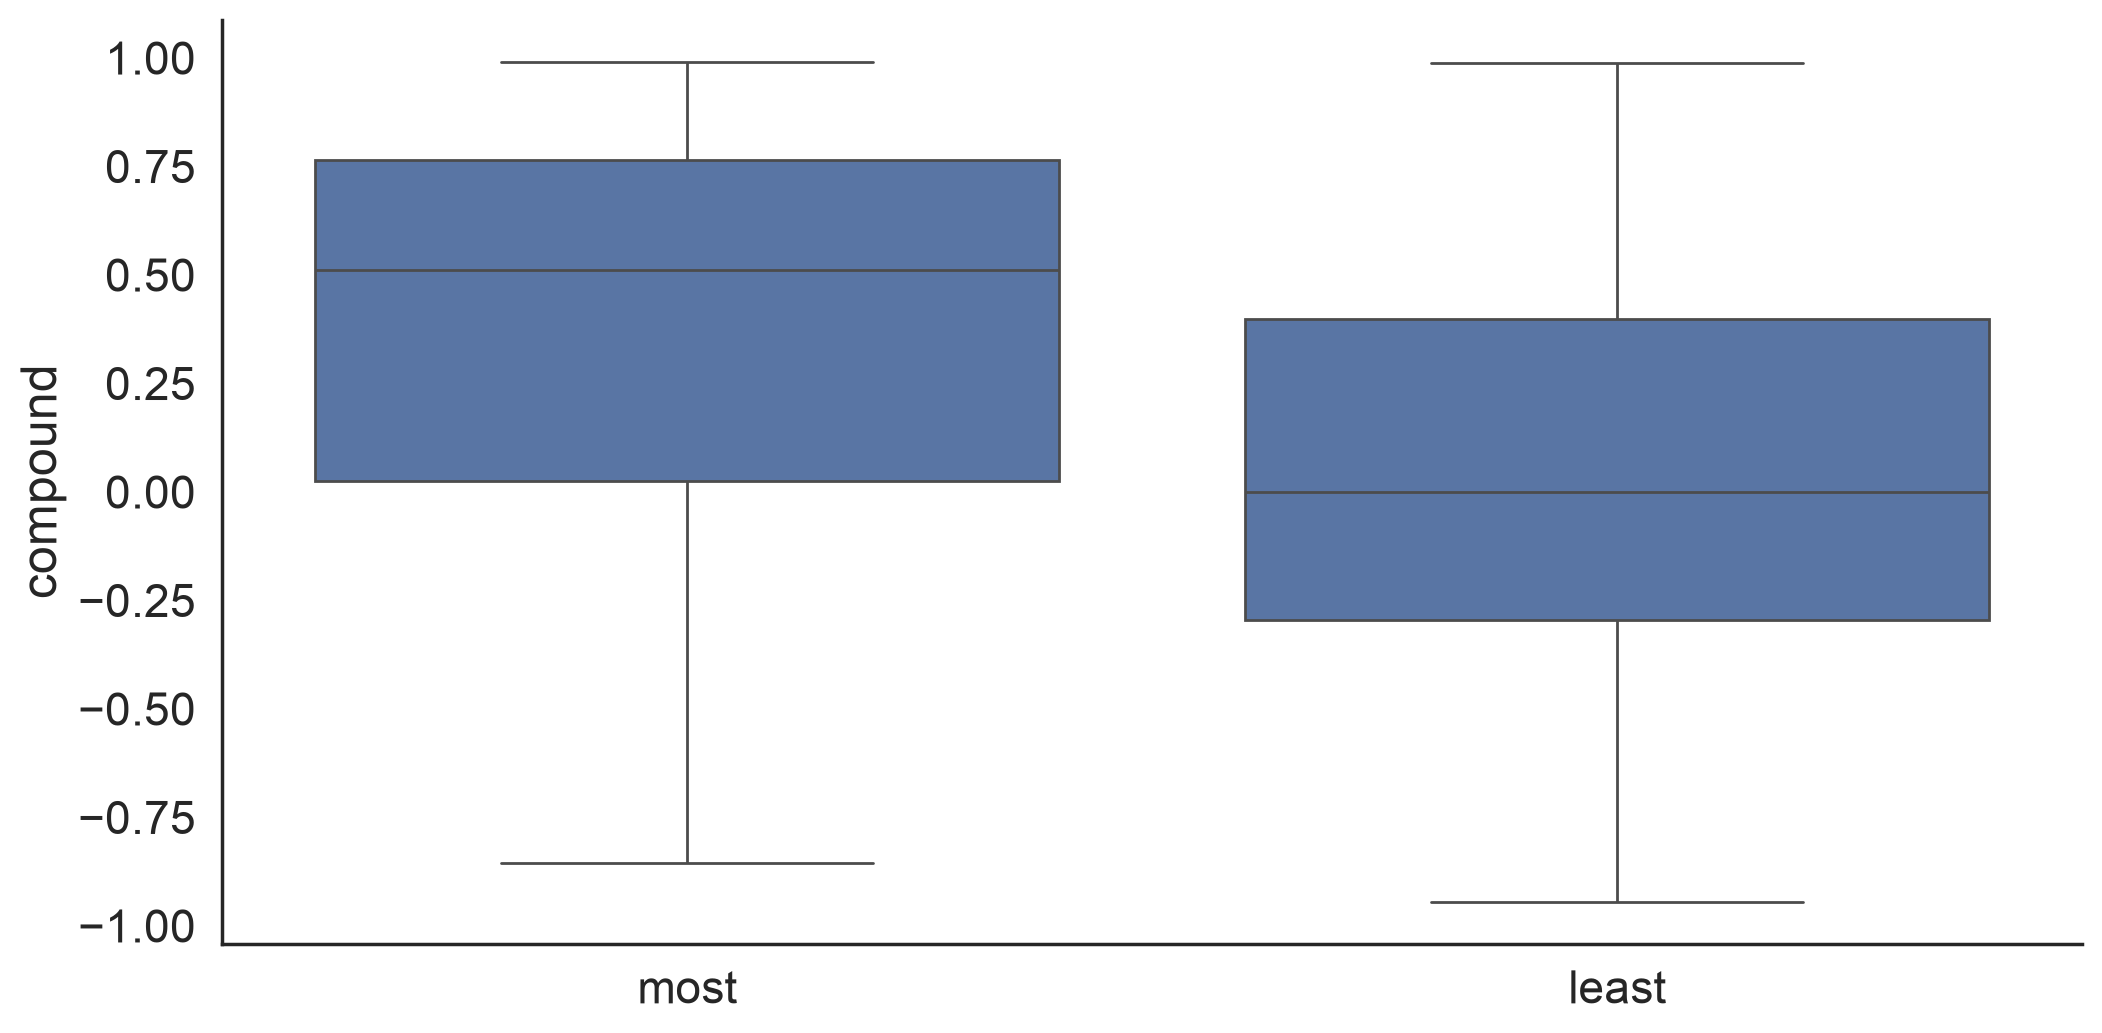

In [38]:
sns.boxplot(data=sentiment, x='question', y='compound')
plt.xlabel('');

Unsurprisingly, what students like most is more positive than what they like least. But look at how many "least" responses score as *positive*:

In [39]:
sentiment.query('question == "least"').sort_values('compound', ascending=False).head(5)

,quarter,question,response,compound
3466,Sp19,least,"The EDA lectures. I like them, but I do not feel like we need to have two of them. I would have liked that time to go towards other topics of data science, or so that we can have topics like runti...",0.9881
4207,Sp20,least,"Sometimes I forget to do the quizzes, which is on me, but some days the quizzes will be worth only 6 points in total and other days it will be worth like 15 points in total, and we only have 20 fr...",0.9874
4517,Sp20,least,"I think the course is too spread out which causes the problem of too little attention for important topics. For example, while I was looking through the Linear Regression videos, I found that the ...",0.9850
5573,Wi24,least,"It feels very overwhelming so far. I have coding experience with COGS 18 and a small amount of MATLAB but the final project seems like something so far out of my reach, and it seems like my group ...",0.9784
6626,Fa26,least,I really would wish that we would be implementing or doing more practice with coding in discussion sections as i feel like this would be really beneficial. Something like more supplemental coding ...,0.9777


In [40]:
# proportion of "least" responses that VADER calls positive
(sentiment.query('question == "least"')['compound'] >= 0.05).mean()

np.float64(0.3864168618266979)

### 6c. Sentiment Over Time <a id="s6c"></a>

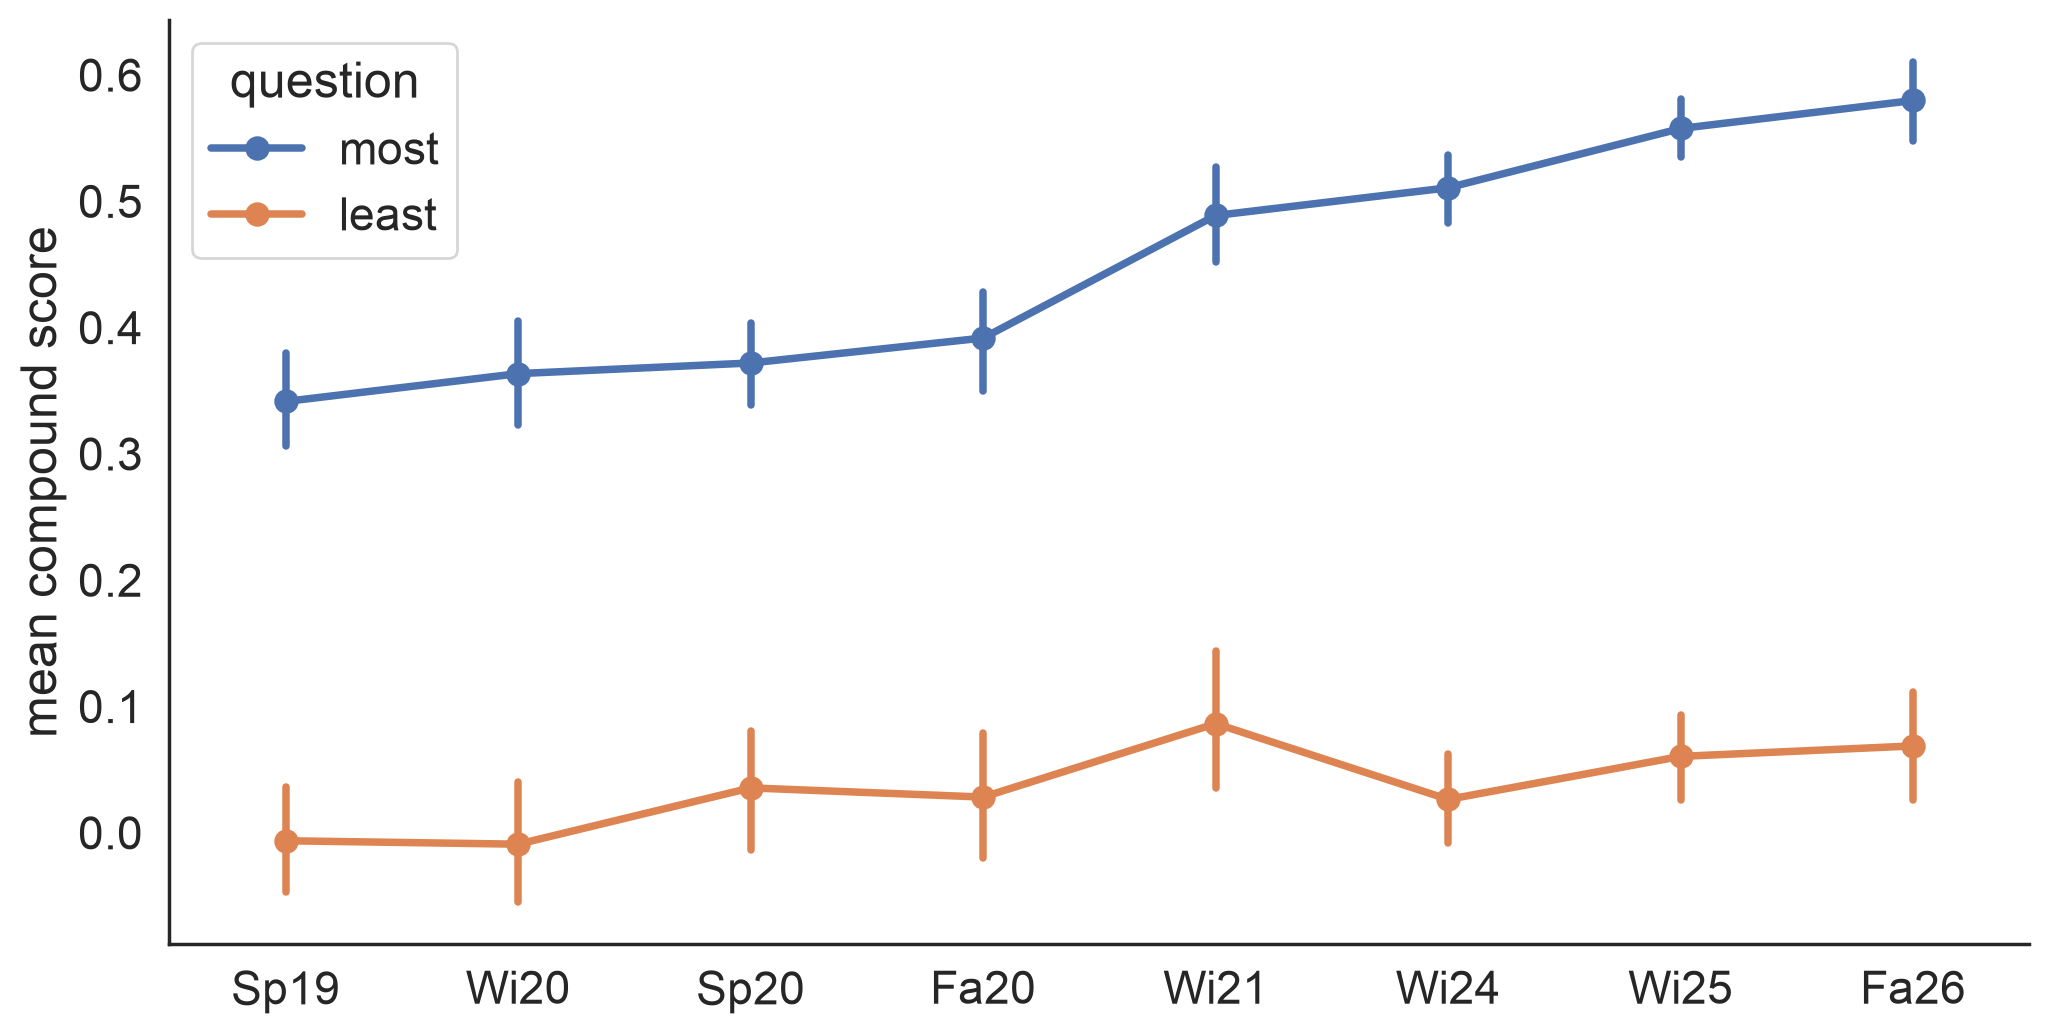

In [41]:
sns.pointplot(data=sentiment, x='quarter', y='compound', hue='question')
plt.ylabel('mean compound score')
plt.xlabel('');

What students enjoy most has gotten steadily more positive since 2019. Are students happier with the course... or is something else going on?

In [42]:
# average number of words per response
sentiment['n_words'] = sentiment['response'].str.split().str.len()
sentiment.groupby(['quarter', 'question'], observed=True)['n_words'].mean().unstack().round(1)

question,least,most
quarter,,
Sp19,18.0,13.0
Wi20,17.5,15.7
Sp20,25.4,18.0
Fa20,23.3,17.5
Wi21,28.1,23.1
Wi24,27.2,21.6
Wi25,29.4,24.2
Fa26,29.9,24.8


Responses have nearly doubled in length since Sp19 (the questions became required in Wi21). VADER's compound score adds up the sentiment of every word, so **longer responses get more extreme scores**. Some of this "trend" may be about how much students write, not how they feel. Always ask what else could explain a pattern.

Either way, sentiment doesn't tell us *what* students are talking about. For that, we need TF-IDF.

## 7. TF-IDF: What's Distinctive About Each Quarter? <a id="s7"></a>

The most *common* words ("assignments", "lectures", "group") show up every quarter, so they don't tell us what made a quarter different. **TF-IDF** (Term Frequency – Inverse Document Frequency) finds the words most distinctive to each document, relative to all the documents in the collection (the **corpus**).

- **Term Frequency (TF):** how often a word occurs in a document
- **Inverse Document Frequency (IDF):** down-weights words that appear in many documents and up-weights words that appear in few

$$IDF_{word} = log\left(\frac{\#\ documents}{\#\ documents\ containing\ word}\right)$$

$$TF\text{-}IDF = TF \times IDF$$

**A word with a high TF-IDF appears a lot in one document and rarely in the others:** the frequency of a term, adjusted for how rarely it's used.

A "document" can be anything: a response, a book, a website, or a whole collection of them.

<div class="alert alert-warning">

**`scikit-learn`'s version is slightly different.** By default, `TfidfVectorizer` uses $IDF = ln\left(\frac{1 + \#\ documents}{1 + \#\ documents\ containing\ word}\right) + 1$, so a word in *every* document gets IDF = 1 instead of 0, and it scales each document's scores so they're comparable across documents of different lengths. Very frequent words can still score fairly high.

</div>

### 7a. One Document per Quarter <a id="s7a"></a>

To ask what's distinctive about each quarter, we combine all of a quarter's "least" responses into **one document per quarter**: 8 documents in our corpus.

In [43]:
# all cleaned "least" responses from a quarter, joined into one long string
least_docs = (df.groupby('quarter', observed=True)['enjoyed_least']
                .apply(lambda responses: ' '.join(clean_text(r) for r in responses)))

# number of words in each document
least_docs.str.split().str.len()

quarter
Sp19     5143
Wi20     4014
Sp20     8556
Fa20     6003
Wi21     8612
Wi24    15223
Wi25    18929
Fa26    13229
Name: enjoyed_least, dtype: int64

### 7b. Calculate TF-IDF <a id="s7b"></a>

First, create a `TfidfVectorizer` object, which will transform our text into vectors (a **bag of words**: one column per word, ignoring word order).

In [44]:
tfidf = TfidfVectorizer(sublinear_tf=True,                         # use log(TF) so very frequent words don't dominate
                        analyzer='word',                           # tokens are words
                        max_features=2000,                         # keep the 2000 most frequent words
                        tokenizer=word_tokenize,                   # nltk's tokenizer
                        stop_words=stopwords.words('english'))     # remove stop words

<div class="alert alert-info">

**A8:** Question 2a asks for a vectorizer with these same five arguments.

</div>

In [45]:
# fit the vectorizer and calculate TF-IDF: one row per document, one column per word
least_tfidf = pd.DataFrame(tfidf.fit_transform(least_docs).toarray(),
                           index=quarters,
                           columns=tfidf.get_feature_names_out())
least_tfidf

,0,00,1,10,100,108,109,11,15,18,...,wrong,wrote,x,year,years,yes,yet,youre,zone,zoom
Sp19,0.000000,0.000000,0.027282,0.018011,0.000000,0.027282,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.029180,0.000000,0.000000,0.000000,0.000000,0.018011,0.000000,0.000000,0.000000
Wi20,0.025428,0.068759,0.037969,0.042441,0.000000,0.043174,0.000000,0.000000,0.000000,0.020223,...,0.020223,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Sp20,0.000000,0.000000,0.037280,0.014145,0.017786,0.021427,0.026558,0.000000,0.033232,0.014145,...,0.049296,0.022917,0.000000,0.000000,0.000000,0.038802,0.023950,0.026558,0.000000,0.037326
Fa20,0.021017,0.000000,0.044052,0.043617,0.021017,0.047810,0.031382,0.000000,0.018712,0.016715,...,0.043617,0.000000,0.000000,0.000000,0.000000,0.000000,0.016715,0.000000,0.000000,0.035585
Wi21,0.000000,0.000000,0.030545,0.000000,0.000000,0.043494,0.000000,0.000000,0.016017,0.034143,...,0.034143,0.000000,0.000000,0.000000,0.000000,0.000000,0.034143,0.000000,0.053034,0.000000
Wi24,0.013870,0.017871,0.009869,0.011031,0.013870,0.040812,0.000000,0.000000,0.020908,0.026323,...,0.011031,0.000000,0.017871,0.037505,0.017871,0.017871,0.032496,0.000000,0.015669,0.013870
Wi25,0.012586,0.027457,0.021369,0.016948,0.012586,0.043805,0.000000,0.037966,0.026739,0.029487,...,0.029487,0.016216,0.034032,0.042316,0.016216,0.016216,0.032003,0.018793,0.024074,0.021309
Fa26,0.014604,0.000000,0.029008,0.011615,0.014604,0.047333,0.000000,0.000000,0.027286,0.011615,...,0.027716,0.000000,0.018817,0.018817,0.018817,0.000000,0.024374,0.000000,0.016498,0.014604


<div class="alert alert-info">

**A8:** Question 2b: same steps. `fit_transform()`, then a DataFrame with the documents as the index and `get_feature_names_out()` as the columns.

</div>

### 7c. Results <a id="s7c"></a>

The single most distinctive word in each quarter's "least" responses: the column with the highest TF-IDF in each row.

In [46]:
least_tfidf.idxmax(axis=1)

Sp19    studies
Wi20        8am
Sp20    quizzes
Fa20    quizzes
Wi21         d3
Wi24       labs
Wi25       labs
Fa26         ai
dtype: object

<div class="alert alert-info">

**A8:** Question 3a: `idxmax(axis=1)` finds the most unique word in each address.

</div>

In [47]:
# the five most distinctive words each quarter
for quarter in quarters:
    print(quarter, least_tfidf.loc[quarter].nlargest(5).index.tolist())

Sp19 ['studies', 'eda', 'case', 'group', 'politics']
Wi20 ['8am', '8', 'lecturers', 'regrade', 'early']
Sp20 ['quizzes', 'video', 'videos', '20', 'quiz']
Fa20 ['quizzes', 'videos', 'quiz', 'project', '1st']
Wi21 ['d3', 'discussion', 'labs', 'like', 'campuswire']
Wi24 ['labs', 'd3', 'like', 'app', 'subscription']
Wi25 ['labs', 'd4', 'ed', 'party', 'assignments']
Fa26 ['ai', 'readings', 'floor', 'seat', 'seats']


This reads like a history of the course: 8 AM lectures (Wi20), quizzes and lecture videos while remote (Sp20, Fa20), discussion labs D1–D8 and CampusWire (Wi21–Wi25), and this quarter... AI, readings, and finding a seat instead of sitting on the floor.

#### Question #4

<img src="QRCodes/14_04.png" width="600" align="right">

In Wi24, students wrote "assignments" 133 times and "labs" 51 times in what they liked least. Yet "labs" has the higher TF-IDF for Wi24. Why?

- A) TF-IDF ignores how often a word appears in a document
- B) "labs" doesn't appear at all in some quarters, so its IDF is higher; "assignments" appears in all 8 documents, so its IDF is as low as it gets
- C) "assignments" was removed as a stop word
- D) "assignments" didn't make the `max_features=2000` cut

Poll: https://forms.gle/yLe3e5WGwYLTk7Xi9

In [48]:
# TF-IDF for Wi24, and how many of the 8 documents (quarters) contain each word
pd.DataFrame({'Wi24 TF-IDF': least_tfidf.loc['Wi24', ['labs', 'assignments']],
              'documents containing word': (least_tfidf[['labs', 'assignments']] > 0).sum()})

,Wi24 TF-IDF,documents containing word
labs,0.068405,5
assignments,0.058130,8


"labs" appears in 5 of the 8 documents; "assignments" in all 8. And because we set `sublinear_tf=True`, TF is log-scaled, so 133 vs. 51 mentions isn't as big a gap as it looks.

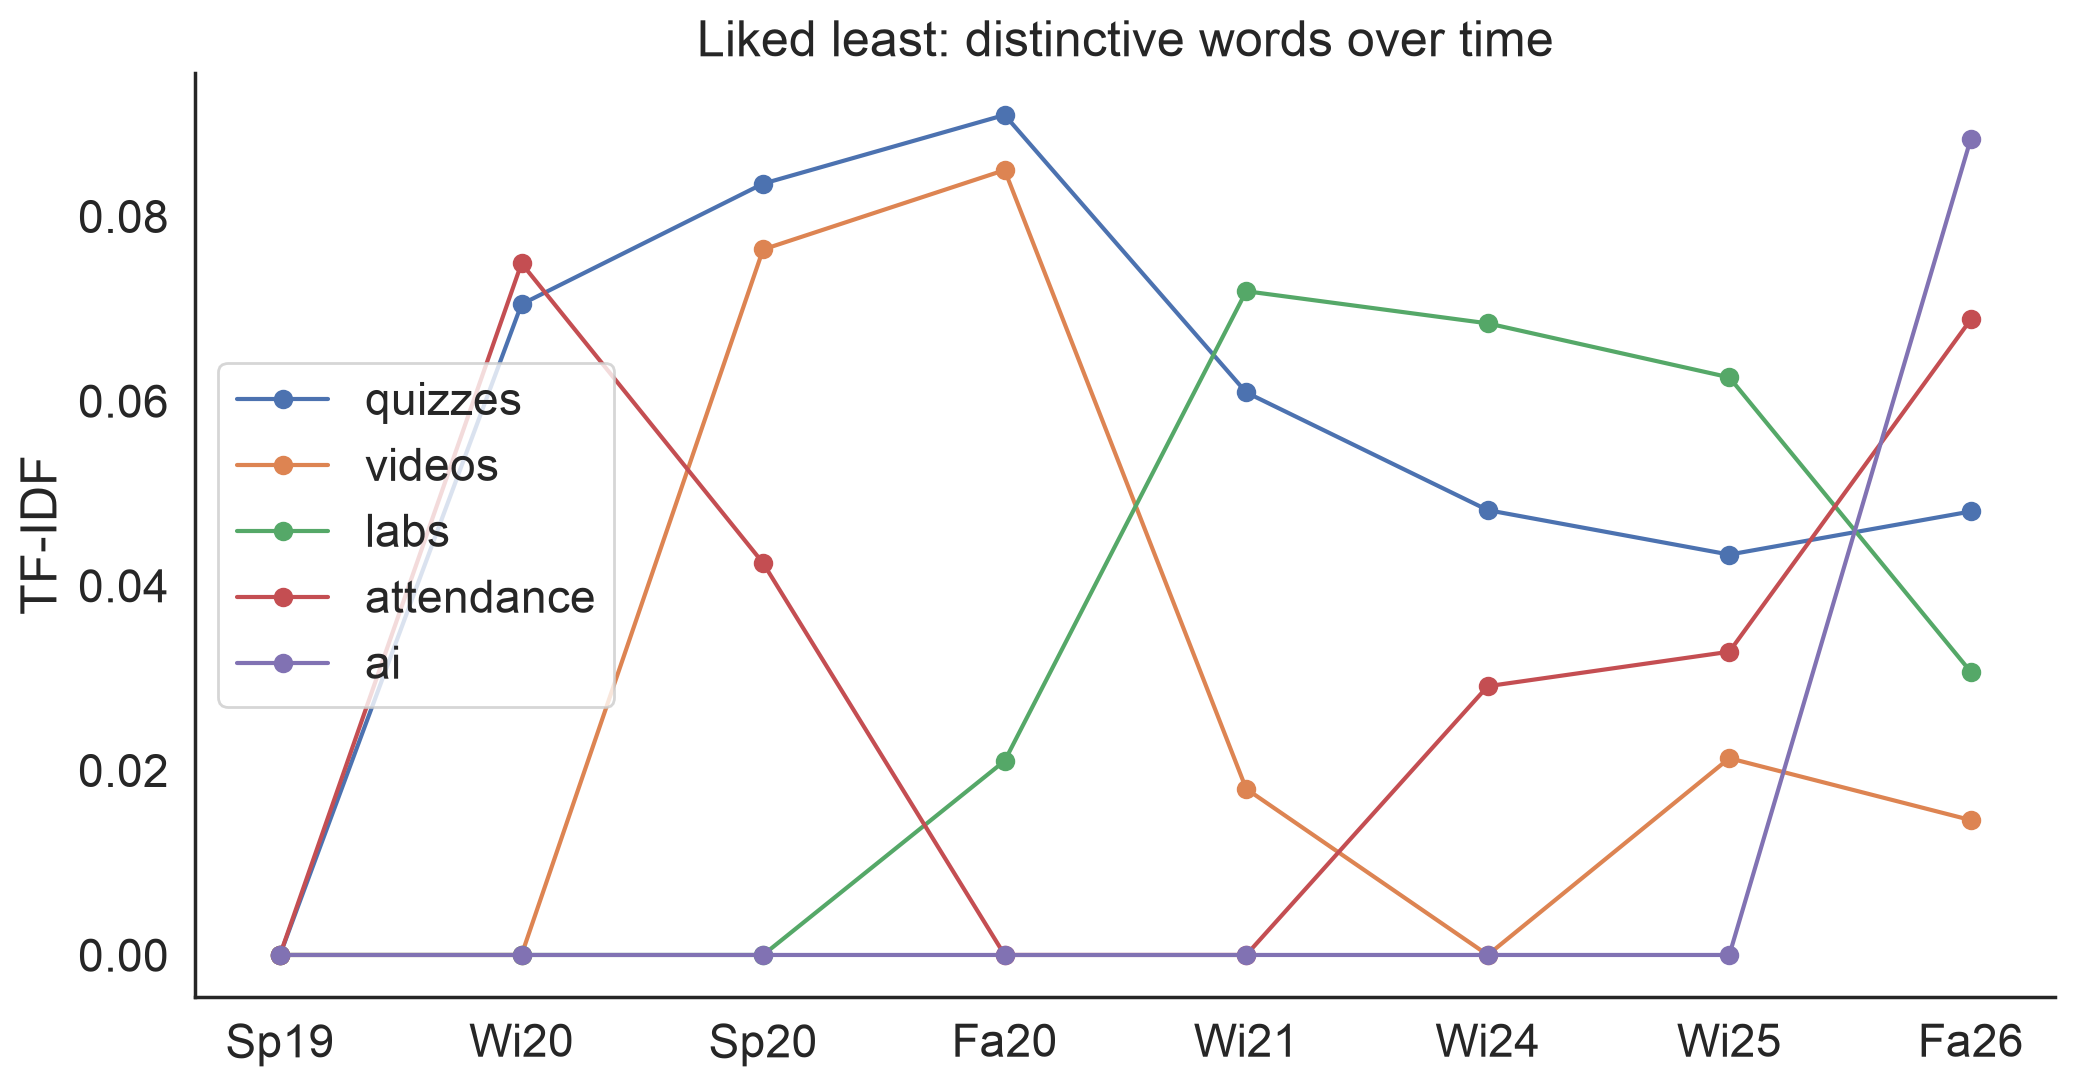

In [49]:
# TF-IDF of a few words across quarters
words = ['quizzes', 'videos', 'labs', 'attendance', 'ai']
least_tfidf[words].plot(marker='o')
plt.ylabel('TF-IDF')
plt.title('Liked least: distinctive words over time');

<div class="alert alert-info">

**A8:** Questions 3b and 3c: the same kind of plot, with years of inaugural addresses instead of quarters.

</div>

The same analysis on what students enjoyed **most**:

In [50]:
most_docs = (df.groupby('quarter', observed=True)['enjoyed_most']
               .apply(lambda responses: ' '.join(clean_text(r) for r in responses)))

most_tfidf = pd.DataFrame(tfidf.fit_transform(most_docs).toarray(),
                          index=quarters,
                          columns=tfidf.get_feature_names_out())

for quarter in quarters:
    print(quarter, most_tfidf.loc[quarter].nlargest(5).index.tolist())

Sp19 ['workbooks', 'assignments', 'data', 'python', 'learning']
Wi20 ['guest', 'data', 'speakers', 'assignments', 'learning']
Sp20 ['video', 'videos', 'short', 'data', 'online']
Fa20 ['videos', 'video', 'data', 'peng', 'vivian']
Wi21 ['data', 'learning', 'remote', 'enjoyed', 'chat']
Wi24 ['data', 'labs', 'enjoyed', 'learning', 'iclicker']
Wi25 ['data', 'enjoyed', 'like', 'labs', 'learning']
Fa26 ['ai', 'activities', 'forms', 'enjoyed', 'like']


Guest speakers (Wi20), short lecture videos (Sp20, Fa20; Vivian Peng was a guest lecturer), labs and clickers (Wi24–Wi25), and this quarter: AI (being allowed to use it, and the course's AI policy), in-class activities and forms. Note that names show up too: TF-IDF finds whatever is distinctive, including things you may not want to report.

## 8. The Same Question, with GenAI <a id="s8"></a>

Everything above is **deterministic**: run the same code on the same data and you'll get exactly the same output, and you can inspect every step.

Now let's ask a large language model (LLM) the same question.

### 8a. The Sample & the Prompt <a id="s8a"></a>

We gave the LLM a random sample: 40 "most" and 40 "least" responses from each quarter (640 responses), not all 6,289 responses from 3,445 students. (The sample was drawn before we removed non-answers, so it includes 17 of them, like "nothing".) Sampling keeps the prompt a manageable length and cost; it also means the LLM sees less data than our code did.

In [ ]:
genai_sample = pd.read_csv('data/COGS108_feedback_genai_sample.csv')
genai_sample.groupby(['quarter', 'question'], sort=False).size().unstack()

**The prompt** (followed by the 640 responses as CSV):

```
Below are anonymous responses to COGS 108 feedback surveys from 8 quarters
(Sp19, Wi20, Sp20, Fa20, Wi21, Wi24, Wi25, Fa26). For each quarter there are
40 randomly sampled answers to what students have enjoyed MOST about the
course so far, and 40 to what they've liked LEAST.

1. Summarize what students like most and least about COGS 108.
2. Describe how this has changed over time, naming specific quarters.
3. Keep it under 350 words and use headers and bullets.

quarter,question,response
Sp19,enjoyed_most,I really like the helpful tutorials on how to use Python libraries
...
```

### 8b. The GenAI Summary <a id="s8b"></a>

*Generated by Claude (Opus 5.5), November 15, 2026, from the 640 sampled responses. Unedited.*

---

**What students like most**
- **Hands-on coding with real data.** In every quarter, the most common answer is learning Python, `pandas` and plotting by working through notebook assignments. Students value step-by-step instructions and assignments that connect to lecture.
- **Lectures and the instructor.** Clear, organized, engaging lectures come up every quarter, especially the interactive parts: clicker questions (2019–2024), and coding along in notebooks with in-class Google Forms (2025–2026).
- **Real-world relevance**, including ethics, guest lectures and seeing past projects.

**What students like least**
- **The jump from lecture to code.** Students say they have to look up syntax to finish assignments, and beginners feel lost.
- **Group project logistics:** coordinating schedules, unresponsive teammates, assigned groups, an open-ended topic.
- **Workload and deadlines**, and learning Git/GitHub.

**How it has changed**
- **Sp19:** assigned groups; politics-based examples felt hard to follow for some international students.
- **Wi20:** the 8 AM lecture time dominates complaints; guest lectures are the most-praised part.
- **Sp20 & Fa20 (remote):** short recorded lecture videos are praised for flexibility; the per-lecture quizzes (one attempt, ambiguous wording) are the biggest complaint by far, along with missing in-person interaction.
- **Wi21:** discussion labs appear: useful practice, but long and hard (D3 in particular).
- **Wi24–Wi25:** weekly labs and quizzes; complaints about vague instructions, everything due on Sunday, and DataHub crashing (Wi25).
- **Fa26:** the group project becomes one of the most-liked parts (working with friends, an open-ended topic, weekly checkpoints), and in-class activities and forms are praised. New complaints: mandatory attendance and the participation policy, finding a seat, discussion sections that feel disconnected from the project, and needing outside help (search or AI) to finish assignments.

**Overall:** Students consistently enjoy applied, hands-on work and engaging lectures. Complaints follow course logistics, which change from quarter to quarter (lecture time, quiz format, labs, attendance), more than course content.

---

That's readable, specific, and took seconds. It also picked up things our deterministic pipeline couldn't easily find, like *why* students disliked the quizzes. But should we believe it?

### 8c. Trust, but Verify <a id="s8c"></a>

Many of the summary's claims can be checked against **all** the data with the tools from Section 4. Here's the percent of responses in each quarter that match a pattern for each claim:

In [51]:
claims = {
    'Sp20 & Fa20: quizzes are the biggest complaint':    ('enjoyed_least', r'\bquiz'),
    'Wi20: the 8 AM lecture time dominates complaints':  ('enjoyed_least', r'\b8\s?am\b|\bearly\b|\bmorning\b'),
    'Sp20 & Fa20: lecture videos are praised':           ('enjoyed_most',  r'\bvideos?\b'),
    'Wi21–Wi25: labs appear':                            ('enjoyed_least', r'\blabs?\b'),
    'Fa26: the group project becomes a most-liked part': ('enjoyed_most',  r'\bgroups?\b|\bteam'),
    'Fa26: complaints about attendance/participation':   ('enjoyed_least', r'attendance|participation'),
    'Fa26: complaints about finding a seat':             ('enjoyed_least', r'\bseats?\b|\bseating\b|\bfloor\b'),
    'Fa26: needing AI to finish assignments':            ('enjoyed_least', r'\bai\b|chatgpt'),
}

verify = pd.DataFrame({claim: df.groupby('quarter', observed=True)[column]
                                .apply(lambda s: s.str.contains(pattern, case=False).mean() * 100)
                       for claim, (column, pattern) in claims.items()}).T

verify.style.format('{:.1f}').background_gradient(axis=1, cmap='Blues')

quarter,Sp19,Wi20,Sp20,Fa20,Wi21,Wi24,Wi25,Fa26
Sp20 & Fa20: quizzes are the biggest complaint,0.0,6.1,36.3,30.2,8.9,7.2,5.1,5.2
Wi20: the 8 AM lecture time dominates complaints,0.0,19.0,0.0,0.3,1.9,1.5,1.7,1.3
Sp20 & Fa20: lecture videos are praised,0.0,0.0,14.6,10.3,0.6,0.0,0.0,0.2
Wi21–Wi25: labs appear,0.0,0.3,0.3,0.3,7.3,9.8,10.6,1.1
Fa26: the group project becomes a most-liked part,6.5,3.7,5.3,5.9,11.8,6.7,13.6,24.6
Fa26: complaints about attendance/participation,0.0,2.4,1.0,0.3,0.0,1.2,1.2,8.7
Fa26: complaints about finding a seat,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.3
Fa26: needing AI to finish assignments,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.2


**Discuss:**
- Which claims hold up across all the data? Which are true but overstated?
- The summary never says *how many* students said something. What's the difference between "a new complaint" that 9% of students mention and one that 2% mention?
- Which claims *can't* be checked with a keyword search (e.g., "the jump from lecture to code")? How would you check those?
- TF-IDF found that "ai" is distinctive in what Fa26 students enjoyed *most* (being allowed to use it, the AI policy). The GenAI summary never mentions it. Why might it have missed this? (Hint: what did the LLM actually read?)

### 8d. GenAI vs. VADER: Sentiment <a id="s8d"></a>

We also asked the LLM to label the sentiment of the 80 Fa26 responses in the sample (positive, neutral or negative, with a short reason), telling it which question each response answered. Let's compare its labels to VADER's, leaving out the 3 non-answers ("nothing", "none", "Nothing in particular.") as we did above.

In [52]:
genai_sentiment = pd.read_csv('data/COGS108_feedback_genai_sentiment.csv')
genai_sentiment = genai_sentiment[~is_non_answer(genai_sentiment['response'])]

# VADER's label for the same responses, using the usual thresholds
genai_sentiment['compound'] = genai_sentiment['response'].apply(get_compound)
genai_sentiment['vader_label'] = np.select([genai_sentiment['compound'] >= 0.05,
                                            genai_sentiment['compound'] <= -0.05],
                                           ['positive', 'negative'], default='neutral')

pd.crosstab(genai_sentiment['genai_label'], genai_sentiment['vader_label'],
            rownames=['GenAI'], colnames=['VADER'], margins=True)

VADER,negative,neutral,positive,All
GenAI,,,,
negative,11,6,12,29
neutral,0,0,2,2
positive,2,6,38,46
All,13,12,52,77


In [53]:
# how often do they agree?
(genai_sentiment['genai_label'] == genai_sentiment['vader_label']).mean()

np.float64(0.6363636363636364)

In [54]:
# where they disagree most: GenAI says negative, VADER says positive
(genai_sentiment
   .query('genai_label == "negative" and vader_label == "positive"')
   .sort_values('compound', ascending=False)
   [['response', 'compound', 'genai_reason']]
   .head(6))

,response,compound,genai_reason
64,"One thing I’ve found challenging is that lecture and discussion attendance are mandatory. I learn better from the recorded lectures because I can pause and rewind them, so that format suits me mor...",0.8735,mandatory attendance; prefers recordings
60,"The GitHub and version control side has been the hardest part to get used to. I’m comfortable with coding but git workflows with a group of five was confusing, especially with merge conflicts. Som...",0.8203,Git workflows confusing; inference lectures fast
63,The freedom to choose any topic. Feels super overwhelming and the ambition of the project is limited by the quarter system.,0.8020,topic freedom feels overwhelming
53,group work. my team is pretty good but I still condisder team work as unneccesary since it could lead to so many unexpected situation,0.4678,sees teamwork as unnecessary
68,Honestly the discussion is not my favorite just because I feel like we could be making more out of our discussion time.,0.4624,discussion time underused
44,Probably the fact that the final project is group based instead of individual and the attendance policy 😔but at the same time I'm also grateful for it because it forces me to attend class.,0.4588,"dislikes group project and attendance, though grateful"


VADER sees "comfortable", "freedom" and "better" and scores these complaints as positive; the LLM reads them as complaints. And "Lectures!" in response to "what did you enjoy most" is neutral to VADER (no sentiment words) but obviously positive in context.

**But who's right?** The LLM's labels aren't the truth either. To know how accurate *either* method is, you'd need people to label a sample by hand and compare both methods to those labels.

#### Question #5

<img src="QRCodes/14_05.png" width="640" align="right">

Which of these tasks is the GenAI approach clearly better suited for than our deterministic pipeline?

- A) Counting exactly how many Fa26 responses mention attendance
- B) Getting identical results every time you rerun the analysis
- C) Grouping responses that say the same thing in different words ("no seats", "sitting on the floor", "overbooked") into one theme
- D) Analyzing all 6,289 responses without sending student data to a third party

Poll: https://forms.gle/89HzEgxYaRNM5Hp27

## 9. Discussion: Standard Text Analysis vs. GenAI <a id="s9"></a>

| | Standard text analysis (counts, VADER, TF-IDF) | GenAI (LLM) |
|---|---|---|
| **Reproducible?** | Yes: same code + same data → same output | Not exactly: output can change from run to run and with model updates |
| **Transparent?** | Every step is inspectable, and you make each choice (stop words, lexicon, `max_features`) | Mostly a black box; it can't fully explain how it got its answer |
| **Scale & cost** | All 6,289 responses in seconds, for free, on your laptop | Limited by prompt length, cost and rate limits (we sampled 640) |
| **Context & meaning** | Weak: "could have been better" is positive; "ai" matches "said"; synonyms are different words | Strong: reads context, mixed feelings, synonyms; knows what question was asked |
| **Output** | Numbers and word lists that *you* have to interpret | Readable themes and explanations, immediately |
| **How it fails** | Predictably and systematically (you can find and fix it) | Plausibly: confident, fluent claims that may be overstated, vague ("many students") or made up |
| **Quantities** | Exact counts and proportions | numbers given may not be computed; typically must request |
| **Privacy** | Data stays on your machine | Data is sent to a company's servers |

**Think-pair-share:**
1. You're asked to report to the department how COGS 108 feedback has changed over time. Which method would you use for *"what percent of students complained about quizzes?"* For *"what kinds of things do students complain about?"*
2. Is it OK to paste these survey responses into a chatbot? What would you want to know first? (Think back to the ethics lecture: consent, who can see the data, how long it's kept.)
3. If you use GenAI on text in your project, how will you show your readers that its output is accurate?

<div class="alert alert-success">

**A workflow that uses both:**
1. Use GenAI on a sample to **brainstorm themes** you might not have thought to look for.
2. Turn the themes into **explicit rules or labels** (keyword patterns, a codebook).
3. **Count** with deterministic code on *all* the data, and look at examples of what each rule matched.
4. **Hand-label a sample** to measure how accurate your rules, or the LLM's labels, actually are.
5. Report your choices (and that you used GenAI, and how).

</div>

## 10. Summary: The Steps <a id="s10"></a>

1. **Start with your question.** It decides which steps you need.
2. **Clean** the text: lowercase, remove punctuation (`re.sub`). Check what your patterns match.
3. **Tokenize**, **remove stop words** (thinking about which ones), and optionally **stem or lemmatize**.
4. **Explore**: word frequencies, words of interest over time.
5. **Measure**: sentiment (lexicon-based, e.g., VADER) and TF-IDF (what's distinctive to each document).
6. **If you use GenAI**, treat its output as a hypothesis to verify, not a result.
7. **Report your choices.** In text analysis, they change your results.

<div class="alert alert-info">

**A8 checklist:** clean with `re` and `.lower()` (5a) · `TfidfVectorizer` with five arguments (7b) · `fit_transform` → DataFrame with an index and `get_feature_names_out()` columns (7b) · `idxmax(axis=1)` (7c) · plot words' TF-IDF over time (7c) · how `max_features` changes results ([11b](#s11b)) · explain your results without jargon.

</div>

## 11. On Your Own <a id="s11"></a>

We won't get to these in lecture, but they're worth working through before A8 and your project.

### 11a. Who Skips the "Most" Question? <a id="s11a"></a>

Nonresponse dropped starting in Wi21, when these questions became required (the survey got shorter overall).

In [ ]:
# blank responses by quarter
(df[['enjoyed_most', 'enjoyed_least']] == '').groupby(df['quarter'], observed=True).sum()

A few students answer what they liked least but leave "most" blank. As an instructor, their feedback is often of particular interest.

In [ ]:
df.loc[(df['enjoyed_most'] == '') & (df['enjoyed_least'] != ''), ['quarter', 'enjoyed_least']]

### 11b. `max_features` <a id="s11b"></a>

`max_features` keeps only the most frequent words across the corpus; any word not in that list can't get a TF-IDF score. In A8, raising it from 2000 to 4000 changes the most unique word for several addresses. Here's what happens with our data:

In [ ]:
def most_unique_words(docs, max_features):
    vectorizer = TfidfVectorizer(sublinear_tf=True, analyzer='word', max_features=max_features,
                                 tokenizer=word_tokenize, stop_words=stopwords.words('english'))
    scores = pd.DataFrame(vectorizer.fit_transform(docs).toarray(),
                          index=quarters, columns=vectorizer.get_feature_names_out())
    print(f'max_features={max_features}: {scores.shape[1]} words kept')
    return scores.idxmax(axis=1)

pd.DataFrame({n: most_unique_words(least_docs, n) for n in [100, 500, 2000, 4000]})

Our corpus only has about 3,600 distinct words after removing stop words, so 2000 and 4000 keep nearly the same vocabulary and the results don't change. With a small vocabulary (100 words), only common words survive, and quarter-specific words like "8am" and "ai" can't be found.

### 11c. Lemmas vs. Stems <a id="s11c"></a>

In [ ]:
df['least_lemmas'] = df['least_words'].apply(lambda words: [lemmatizer.lemmatize(w) for w in words])

pd.concat([top_words(df['least_words'], 10).add_prefix('words: '),
           top_words(df['least_stems'], 10).add_prefix('stems: '),
           top_words(df['least_lemmas'], 10).add_prefix('lemmas: ')], axis=1)

### 11d. Bigrams <a id="s11d"></a>

Single words lose context: "group" vs. "group project", "office" vs. "office hours." `ngram_range=(2, 2)` makes each pair of adjacent words a token.

In [ ]:
bigram_tfidf = TfidfVectorizer(sublinear_tf=True, ngram_range=(2, 2), max_features=5000,
                               tokenizer=word_tokenize, stop_words=stopwords.words('english'))

least_bigrams = pd.DataFrame(bigram_tfidf.fit_transform(least_docs).toarray(),
                             index=quarters, columns=bigram_tfidf.get_feature_names_out())

for quarter in quarters:
    print(quarter, least_bigrams.loc[quarter].nlargest(4).index.tolist())

### 11e. Run the GenAI Prompt Yourself <a id="s11e"></a>

Paste the prompt from [8a](#s8a) and the contents of `data/COGS108_feedback_genai_sample.csv` into an AI tool (or ask it to analyze the attached file). Then compare:
- Do you get the same summary as 8b? The same themes, in the same order?
- Ask it for the percent of Fa26 students who mention attendance. Does its number match `check_word_freq(df, 'attendance')`?
- Ask it to give you quotes for a theme. Are the quotes really in the data? (Search for them with `str.contains`.)

You can also call an LLM from Python with a provider's API (this needs an account and an API key, and costs money per request). The general pattern looks like this (not run here):

```python
from anthropic import Anthropic          # or another provider's package

client = Anthropic()                     # reads your API key from an environment variable
message = client.messages.create(
    model="<model name>",
    max_tokens=1000,
    messages=[{"role": "user", "content": prompt + genai_sample.to_csv(index=False)}],
)
print(message.content[0].text)
```

Before sending data anywhere, check that you're allowed to: who collected it, what participants agreed to, and what the provider does with what you send.

### 11f. Preview: Text as Features in a Model <a id="s11f"></a>

Could a model tell from the words alone whether a response answered "most" or "least"? TF-IDF turns each response into a row of numbers, which a classifier can use, just like in the machine learning lecture.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

X = sentiment['response']
y = sentiment['question']

model = Pipeline([('tfidf', TfidfVectorizer(sublinear_tf=True, stop_words='english')),
                  ('logreg', LogisticRegression(max_iter=1000))])

print('mean 5-fold CV accuracy:', cross_val_score(model, X, y, cv=5).mean().round(3))

In [ ]:
# which words push a prediction toward "most" vs. "least"?
model.fit(X, y)
coefs = pd.Series(model.named_steps['logreg'].coef_[0],
                  index=model.named_steps['tfidf'].get_feature_names_out())
print('classes:', model.named_steps['logreg'].classes_, '(positive coefficients → second class)')
print('toward "most": ', coefs.nlargest(10).index.tolist())
print('toward "least":', coefs.nsmallest(10).index.tolist())